# Анализ эффективности маркетинговых компаний в социальных сетях для выявления закономерностей вовлечения аудитории

Комаров Иван ИД24-2

## 2.1. Постановка задачи

**Бизнес-проблема:**
Высокие показатели охвата, кликов и вовлечённости не всегда означают эффективное использование рекламного бюджета. Поэтому необходимо определить, какие характеристики рекламных кампаний и аудитории связаны с более высокой финансовой отдачей.

**Бизнес-цель:**
Повысить эффективность расходования рекламного бюджета за счёт выявления наиболее результативных маркетинговых стратегий и сегментов аудитории.

**Критерии достижения:**
- выявить стратегии и сегменты аудитории с более высокой финансовой эффективностью;
- определить направления перераспределения рекламного бюджета;
- проверить, позволяет ли учёт дополнительных факторов улучшить прогноз ROAS;
- оценить потенциальное повышение финансовой отдачи на основе ретроспективного анализа.

**Практическая ценность:**
Результаты могут использоваться для выбора более эффективных рекламных стратегий, сегментов аудитории и поддержки решений по распределению рекламного бюджета.

**Объект исследования:**
Онлайн-маркетинговые кампании в социальных сетях.

**Предмет исследования:**
Методы анализа разнородных данных и машинного обучения для оценки финансовой эффективности маркетинговых кампаний и выявления закономерностей вовлечения аудитории.

**Границы исследования:**
Исследование проводится на данных рекламных кампаний Meta Ads в сфере e-commerce. В качестве предметной области рассматриваются товары кофейной тематики. Используются недельные данные рекламных кампаний и внешние источники, характеризующие информационный и потребительский контекст.

**Исследовательский вопрос:**
Какие характеристики рекламных кампаний, аудитории и внешнего контекста связаны с различиями в финансовой эффективности маркетинговых кампаний?

**Гипотеза:**

H1: характеристики рекламных кампаний, аудитории и внешний контекст связаны с ROAS и позволяют улучшить его прогноз.

H0: эти факторы не имеют значимой связи с ROAS и не улучшают прогноз.

## 2.2. Подбор и изучение источников данных

В качестве предметной области выбран сегмент e-commerce, связанный с кофейной продукцией. Выбор обусловлен тем, что основной набор данных содержит реальные рекламные кампании Meta Ads для интернет-магазина данной тематики, а внешние источники позволяют дополнить их информацией об общественном интересе, отраслевом новостном фоне и потребительских обзорах за тот же временной период. Непосредственно для самого исследования были выбраны четыре взаимодополняющих источника. Они относятся к одной предметной области, имеют общий календарный период и могут быть приведены к одной недельной шкале. Mendeley содержит целевой показатель ROAS и характеристики кампаний. Остальные источники формируют наблюдаемый внешний контекст недели.

| Источник | Происхождение и формат | Исходный grain | Фактический объём и период | Роль и способ объединения |
|---|---|---|---|---|
| Mendeley Meta Ads | Технический университет Либерца (Чехия); лицензия CC BY 4.0 | кампания * неделя | 1 872 строки; 36 кампаний; 52 недели; 04.08.2024–27.07.2025 | основной реляционный набор; левая сторона объединения |
| Wikimedia Analytics API | официальный Pageviews REST API; JSON | статья × тип доступа × день | 3 276 записей; 3 статьи × 3 типа доступа × 364 дня; 04.08.2024–02.08.2025 | показатель общественного интереса; агрегация по неделе и `LEFT JOIN` по `Date` |
| Daily Coffee News | публичный RSS издательства Roast Magazine; XML | публикация | 624 публикации; 05.08.2024–01.08.2025 | отраслевой новостной контекст; агрегация по неделе и `LEFT JOIN` по `Date` |
| CoffeeReview | официальный RSS обзоров; XML с неструктурированным текстом | обзор | 604 обзора; 05.08.2024–31.07.2025 | профессиональный обзорный и текстовый контекст; агрегация по неделе и `LEFT JOIN` по `Date` |

Внешние данные собирались до 02.08.2025, чтобы полностью охватить последнюю неделю наблюдений основного набора.

### Общие правила загрузки и проверки

Следующая ячейка подключает библиотеки и определяет единые функции для загрузки, очистки HTML, формирования воскресной недели и первичного профилирования. Проверенные ответы API и RSS сохраняются в локальном кэше `course_data`: повторный запуск использует те же исходные записи, а при отсутствии кэша обращается к официальным URL. Это снижает нагрузку на источники и делает результат воспроизводимым.

In [1]:
from pathlib import Path
from io import StringIO
import html
import json
import re
import time
import urllib.parse
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup
from IPython.display import display
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

DATA_DIR = Path("course_data")
DATA_DIR.mkdir(exist_ok=True)
START_DATE = pd.Timestamp("2024-08-04")
END_DATE = pd.Timestamp("2025-08-02")
EXPECTED_WEEKS = pd.date_range(START_DATE, END_DATE - pd.Timedelta(days=1), freq="7D")

HEADERS = {
    "User-Agent": "academic-coursework/1.0 (public data research; contact: student project)"
}


def sunday_week_start(values):
    """Приводит дату к воскресенью, с которого начинается соответствующая неделя."""
    dates = pd.to_datetime(values, utc=True, errors="raise")
    if isinstance(dates, pd.Series):
        dates = dates.dt.tz_convert(None).dt.normalize()
        dayofweek = dates.dt.dayofweek
    else:
        dates = dates.tz_convert(None).normalize()
        dayofweek = dates.dayofweek
    return dates - pd.to_timedelta((dayofweek + 1) % 7, unit="D")


def html_to_text(value):
    """Удаляет HTML, декодирует сущности и нормализует пробелы."""
    text = BeautifulSoup(str(value or ""), "html.parser").get_text(" ")
    text = html.unescape(text)
    return re.sub(r"\s+", " ", text).strip()


def compact_profile(df, name, date_col=None, key_cols=None):
    print(f"{name}: shape={df.shape}")
    print("Типы данных:")
    display(df.dtypes.rename("dtype").to_frame())
    missing = df.isna().sum()
    print(f"Пропусков всего: {int(missing.sum())}")
    display(missing[missing.gt(0)].rename("missing").to_frame())
    if date_col is not None:
        raw_dates = df[date_col].astype("string")
        date_format = "%Y%m%d%H" if raw_dates.str.fullmatch(r"\d{10}").all() else None
        dates = pd.to_datetime(df[date_col], format=date_format, utc=True, errors="coerce")
        print("Диапазон дат:", dates.min(), "—", dates.max())
    if key_cols is not None:
        print(f"Дубликатов ключа {key_cols}: {int(df.duplicated(key_cols).sum())}")
    display(df.head(3))


def parse_rss_items(xml_bytes):
    root = ET.fromstring(xml_bytes)
    ns = {
        "dc": "http://purl.org/dc/elements/1.1/",
        "content": "http://purl.org/rss/1.0/modules/content/",
    }
    records = []
    for item in root.findall(".//item"):
        def value(tag):
            node = item.find(tag, ns)
            return "" if node is None or node.text is None else node.text
        records.append({
            "title": value("title"),
            "link": value("link"),
            "guid": value("guid"),
            "creator": value("dc:creator"),
            "pubDate": value("pubDate"),
            "description": value("description"),
            "content_encoded": value("content:encoded"),
            "categories": [node.text for node in item.findall("category") if node.text],
        })
    return records


def crawl_rss(feed_template, start_date, end_date, max_pages=250):
    """Читает архивные RSS-страницы до прохождения нижней границы периода."""
    collected = []
    crossed_start = False
    for page in range(1, max_pages + 1):
        url = feed_template.format(page=page)
        response = requests.get(url, headers=HEADERS, timeout=60)
        response.raise_for_status()
        items = parse_rss_items(response.content)
        if not items:
            break
        page_dates = pd.to_datetime([x["pubDate"] for x in items], utc=True, errors="coerce")
        for record, pub_date in zip(items, page_dates):
            if pd.notna(pub_date) and start_date <= pub_date.tz_convert(None) <= end_date + pd.Timedelta(days=1):
                record["source_page"] = page
                collected.append(record)
        valid_dates = page_dates[~pd.isna(page_dates)]
        if len(valid_dates) and valid_dates.min().tz_convert(None) < start_date:
            crossed_start = True
            break
        time.sleep(0.05)
    if not crossed_start:
        raise RuntimeError("RSS-архив не был дочитан до начала исследуемого периода")
    return collected

print("Каталог данных:", DATA_DIR.resolve())
print("Целевой недельный диапазон:", EXPECTED_WEEKS.min().date(), "—", EXPECTED_WEEKS.max().date())

Каталог данных: /home/agent/how_to_social_marketing_correct/course_data
Целевой недельный диапазон: 2024-08-04 — 2025-07-27


Общие функции задают одинаковое правило недели для всех источников и позволяют далее проверять фактическую структуру каждого набора сопоставимым способом.

### Источник 1. Рекламные кампании Meta Ads из Mendeley Data

Основной набор опубликован Т. Семерадовой и П. Вайнлих в репозитории Mendeley Data и связан со статьёй о широте и глубине персонализации рекламы. Набор содержит 36 повторно наблюдаемых кампаний: каждая конфигурация представлена в течение 52 недель. Поле `ROAS` используется как опубликованный целевой показатель.

In [2]:
MENDELEY_PATH = DATA_DIR / "mendeley_campaign.csv"
MENDELEY_PAGE = "https://data.mendeley.com/datasets/hh7xps83z5/1"
MENDELEY_FILE_URL = "https://data.mendeley.com/public-files/datasets/hh7xps83z5/files/04b5d7d8-82f6-4e77-a5f2-45ca073fe12d/file_downloaded"

if not MENDELEY_PATH.exists():
    try:
        from playwright.sync_api import sync_playwright
        with sync_playwright() as playwright:
            browser = playwright.chromium.launch(headless=True)
            page = browser.new_page()
            page.goto(MENDELEY_PAGE, wait_until="domcontentloaded", timeout=120_000)
            response = page.request.get(MENDELEY_FILE_URL, timeout=120_000)
            if not response.ok:
                raise RuntimeError(f"Mendeley download failed: HTTP {response.status}")
            MENDELEY_PATH.write_bytes(response.body())
            browser.close()
    except Exception as exc:
        raise RuntimeError(
            "Не удалось получить официальный CSV Mendeley. "
            "Сохраните Coffeeshop_Personalization_Campaign_Data.csv как "
            f"{MENDELEY_PATH}. Причина: {exc}"
        ) from exc

campaign_raw = pd.read_csv(MENDELEY_PATH)
compact_profile(
    campaign_raw,
    "Mendeley Meta Ads",
    date_col="Date",
    key_cols=["Campaign_ID", "Date"],
)
print("Уникальных кампаний:", campaign_raw["Campaign_ID"].nunique())
print("Уникальных недель:", campaign_raw["Date"].nunique())
print("Уровни Funnel:", sorted(campaign_raw["Funnel"].unique()))
print("Уровни Audience:", sorted(campaign_raw["Audience"].unique()))

Mendeley Meta Ads: shape=(1872, 11)
Типы данных:


,dtype
Campaign_ID,str
Date,str
Funnel,str
Retargeting,str
Audience,str
Creative,str
Audience_Size,int64
CTR,float64
Conversions,int64
ROAS,float64


Пропусков всего: 0


,missing


Диапазон дат: 2024-08-04 00:00:00+00:00 — 2025-07-27 00:00:00+00:00
Дубликатов ключа ['Campaign_ID', 'Date']: 0


,Campaign_ID,Date,Funnel,Retargeting,Audience,Creative,Audience_Size,CTR,Conversions,ROAS,Spend
0,CAMP_01,2024-08-04,TOFU,Standard,Custom,Low,902,1.26,0,2.52,197.87
1,CAMP_01,2024-08-11,TOFU,Standard,Custom,Low,921,0.49,0,2.71,202.83
2,CAMP_01,2024-08-18,TOFU,Standard,Custom,Low,1463,1.08,0,2.39,420.92


Уникальных кампаний: 36
Уникальных недель: 52
Уровни Funnel: ['BOFU', 'MOFU', 'TOFU']
Уровни Audience: ['Custom', 'Lookalike_1%', 'Lookalike_5%']


Проверка подтверждает 1 872 строки, 36 кампаний и 52 воскресные даты без пропусков. Каждая дата содержит 36 кампаний, а каждая кампания наблюдается 52 раза.

#### Шкалы и характеристики Mendeley

| Поле | Шкала |
|---|---|
| `Campaign_ID` | номинальная |
| `Date` | интервальная |
| `Funnel` | порядковая |
| `Retargeting` | дихотомическая |
| `Audience` | категориальная |
| `Creative` | порядковая |
| `Audience_Size` | абсолютная |
| `Conversions` | абсолютная |
| `CTR` | отношений |
| `ROAS` | отношений |
| `Spend` | отношений |

### Источник 2. Wikimedia Analytics API

Второй источник является официальным программным интерфейсом Wikimedia, который предоставляет статистику просмотров страниц проектов Wikimedia, включая Wikipedia. Через API можно получать временные ряды по отдельным статьям с разбивкой по датам и типам доступа.

Источник выбран как независимый показатель внешнего интереса аудитории к кофейной тематике. Для оценки внешнего интереса выбраны статьи Coffee, Coffeehouse и Espresso, поскольку они отражают соответственно общий интерес к категории кофе, интерес к кофейной культуре и интерес к одному из наиболее распространённых видов кофейных напитков. Просмотры этих статей позволяют оценить, насколько меняется общественный интерес к предметной области во времени, независимо от конкретных рекламных кампаний. Эти данные используются как внешний фактор, потенциально связанный с изменением ROAS.

На уровне недели рассчитываются общий объём просмотров, максимальный дневной интерес, стандартное отклонение дневных просмотров и доля просмотров за выходные. Эти показатели описывают соответственно масштаб, пик, нестабильность и недельную структуру интереса.

In [3]:
WIKI_PATH = DATA_DIR / "wikimedia_pageviews.json"
ARTICLES = ["Coffee", "Espresso", "Coffeehouse"]
ACCESS_TYPES = ["desktop", "mobile-web", "mobile-app"]

if WIKI_PATH.exists():
    wiki_payload = json.loads(WIKI_PATH.read_text(encoding="utf-8"))
else:
    wiki_items = []
    for article in ARTICLES:
        for access in ACCESS_TYPES:
            encoded_article = urllib.parse.quote(article, safe="")
            url = (
                "https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article/"
                f"en.wikipedia/{access}/user/{encoded_article}/daily/2024080400/2025080200"
            )
            response = requests.get(url, headers=HEADERS, timeout=60)
            response.raise_for_status()
            wiki_items.extend(response.json()["items"])
    wiki_payload = {"items": wiki_items}
    WIKI_PATH.write_text(json.dumps(wiki_payload, ensure_ascii=False), encoding="utf-8")

wiki_raw = pd.json_normalize(wiki_payload["items"])
compact_profile(
    wiki_raw,
    "Wikimedia Pageviews",
    date_col="timestamp",
    key_cols=["article", "access", "timestamp"],
)
print("Статьи:", sorted(wiki_raw["article"].unique()))
print("Типы доступа:", sorted(wiki_raw["access"].unique()))
print("Уникальных дневных дат:", wiki_raw["timestamp"].nunique())
print("Диапазон views:", int(wiki_raw["views"].min()), "—", int(wiki_raw["views"].max()))

Wikimedia Pageviews: shape=(3276, 7)
Типы данных:


,dtype
project,str
article,str
granularity,str
timestamp,str
access,str
agent,str
views,int64


Пропусков всего: 0


,missing


Диапазон дат: 2024-08-04 00:00:00+00:00 — 2025-08-02 00:00:00+00:00
Дубликатов ключа ['article', 'access', 'timestamp']: 0


,project,article,granularity,timestamp,access,agent,views
0,en.wikipedia,Coffee,daily,2024080400,desktop,user,740
1,en.wikipedia,Coffee,daily,2024080500,desktop,user,915
2,en.wikipedia,Coffee,daily,2024080600,desktop,user,985


Статьи: ['Coffee', 'Coffeehouse', 'Espresso']
Типы доступа: ['desktop', 'mobile-app', 'mobile-web']
Уникальных дневных дат: 364
Диапазон views: 5 — 1617


Wikimedia API предоставил данные по трём тематическим статьям и трём типам доступа за 364 дня. Пропуски в показателе просмотров отсутствуют, дубликаты по сочетанию `article + access + timestamp` не обнаружены.

Для дальнейшего анализа используются как исходные характеристики API, так и производные недельные показатели, отражающие общий объём интереса, максимальную дневную активность, изменчивость просмотров и долю просмотров в выходные дни.

| Поле | Шкала |
|---|---|
| `article` | категориальная |
| `access` | категориальная |
| `day_type` | дихотомическая |
| `timestamp` | интервальная |
| `views` | абсолютная |
| `wiki_views` | абсолютная |
| `wiki_peak_daily_views` | абсолютная |
| `wiki_daily_views_std` | отношений |
| `wiki_weekend_share` | отношений |

### Источник 3. Daily Coffee News RSS

Третий источник представляет собой отраслевое издание Roast Magazine, посвящённое кофейной индустрии. В публикациях рассматриваются рыночные новости, продукты, розничная торговля, маркетинг, производство и другие события отрасли.

Источник выбран для оценки информационного фона, в котором проходили маркетинговые кампании. Если в определённые недели кофейная тематика активнее присутствует в отраслевых публикациях, это может отражать изменение внешнего контекста и интереса к рынку, потенциально связанного с эффективностью рекламы.

RSS предоставляет дату публикации, автора, тематические категории, заголовок и текстовое описание материала. Это позволяет учитывать как интенсивность новостного потока, так и его структуру. В дальнейшем публикации агрегируются по неделям, совпадающим с недельной детализацией основного набора рекламных кампаний.

In [4]:
NEWS_PATH = DATA_DIR / "daily_coffee_news_items.json"

if NEWS_PATH.exists():
    news_raw = pd.read_json(NEWS_PATH)
else:
    news_records = crawl_rss(
        "https://dailycoffeenews.com/feed/?paged={page}",
        START_DATE,
        END_DATE,
    )
    news_raw = pd.DataFrame(news_records)
    NEWS_PATH.write_text(news_raw.to_json(orient="records", force_ascii=False, date_format="iso"), encoding="utf-8")

news_date_col = "pubDate" if "pubDate" in news_raw.columns else "date"
compact_profile(
    news_raw,
    "Daily Coffee News",
    date_col=news_date_col,
    key_cols=["guid"],
)
news_categories = sorted({category for values in news_raw["categories"] for category in values})
print("Уникальных авторов:", news_raw["creator"].nunique())
print("Уникальных категорий:", len(news_categories))
print("Примеры категорий:", news_categories[:20])
print("Дубликатов link:", int(news_raw.duplicated("link").sum()))

Daily Coffee News: shape=(624, 10)
Типы данных:


,dtype
date,"datetime64[us, UTC]"
title,str
link,str
guid,str
creator,str
description,str
categories,object
page,int64
Date,datetime64[us]
desc_text,str


Пропусков всего: 0


,missing


Диапазон дат: 2024-08-05 13:20:47+00:00 — 2025-08-01 13:13:46+00:00
Дубликатов ключа ['guid']: 0


,date,title,link,guid,creator,description,categories,page,Date,desc_text
0,2025-08-01 13:13:46+00:00,Black Rock Coffee Bar Reportedly Files Confide...,https://dailycoffeenews.com/2025/08/01/black-r...,https://dailycoffeenews.com/?p=189978,Daily Coffee News Staff,"<div><img width=""620"" height=""414"" src=""https:...","[Business Operations, Corporate, Industry, Mar...",76,2025-07-27,After several years of rapid retail expansion ...
1,2025-08-01 12:05:24+00:00,Weekly Coffee News: Cold Brew Manufacturing Sa...,https://dailycoffeenews.com/2025/08/01/weekly-...,https://dailycoffeenews.com/?p=189820,Daily Coffee News Staff,"<div><img width=""620"" height=""434"" src=""https:...","[Columns, Weekly Coffee News]",76,2025-07-27,Welcome to DCN’s Weekly Coffee News! Subscribe...
2,2025-07-31 16:24:24+00:00,Danone Sues Chobani Over ‘Bright & Mellow’ Col...,https://dailycoffeenews.com/2025/07/31/danone-...,https://dailycoffeenews.com/?p=189953,Nick Brown,"<div><img width=""620"" height=""465"" src=""https:...","[Corporate, Craft/Operations, Industry, Macro,...",76,2025-07-27,Two yogurt giants are now locked into a legal ...


Уникальных авторов: 26
Уникальных категорий: 3558
Примеры категорий: ['"Modulating the Flavor Profile of Coffee"', '1% for the Planet', '1105 West Peachtree', '11th Hour Coffee', '2023 Roaster of the Year', '2024 Year In Review', '2025 Coffee Annuals', '2025 Roaster of the Year', '2026 Roaster of the Year', '3D Printing and Additive Manufacturing', '3D printing', '3Temp', '3Temp Hipster', '3Temp Kobra', '3Temp Puls', '3Temp Wall', '3fconcept', '4C', '517 Coffee', '60 Decibels']
Дубликатов link: 0


За исследуемый период получено 624 публикации без повторов. Материалы написаны 26 авторами и относятся к различным тематическим направлениям, среди которых встречаются Industry, Marketing, Retail, Roasting, Market News и Origin. Это позволяет использовать источник не только для оценки общего объёма новостной активности, но и для характеристики структуры отраслевого информационного фона.

Для дальнейшего анализа используются как исходные признаки публикаций, так и недельные показатели, рассчитанные на их основе.

| Поле | Шкала |
|---|---|
| `creator` | категориальная |
| `category` | категориальная |
| `publication_weekday` | категориальная |
| `title`, `description` | контентная |
| `pubDate` | интервальная |
| `news_count` | абсолютная |
| `news_unique_authors` | абсолютная |
| `news_text_chars` | абсолютная |

Недельные показатели отражают интенсивность публикационной активности, разнообразие авторов и общий объём информационного материала. Эти характеристики далее используются как показатели внешнего отраслевого контекста рекламных кампаний.

### Источник 4. CoffeeReview RSS

Четвертый специализированный источник состоит из обзоров кофе, содержащих тексты профессиональных оценок и описаний продукции. Он выбран для того, чтобы дополнить данные рекламных кампаний показателями потребительского и экспертного интереса к кофейной тематике.

В отличие от Daily Coffee News, который отражает отраслевой информационный фон, CoffeeReview характеризует именно обзорный и оценочный контекст. Это позволяет учитывать, насколько активно в разные недели публиковались материалы о кофейной продукции и какой объём текстового контента формировался вокруг неё.

Для каждой публикации доступны дата, автор, заголовок, краткое описание и расширенный текст. Эти поля используются как неструктурированные данные, которые далее очищаются, преобразуются в текстовые признаки и агрегируются по неделям для объединения с данными рекламных кампаний.

In [5]:
REVIEW_PATH = DATA_DIR / "coffee_review_items.json"

if REVIEW_PATH.exists():
    reviews_raw = pd.read_json(REVIEW_PATH)
else:
    review_records = crawl_rss(
        "https://www.coffeereview.com/review/feed/?paged={page}",
        START_DATE,
        END_DATE,
    )
    reviews_raw = pd.DataFrame(review_records)
    REVIEW_PATH.write_text(reviews_raw.to_json(orient="records", force_ascii=False, date_format="iso"), encoding="utf-8")

compact_profile(
    reviews_raw,
    "CoffeeReview",
    date_col="pubDate",
    key_cols=["guid"],
)
print("Уникальных авторов:", reviews_raw["creator"].nunique())
print("Непустых description:", int(reviews_raw["description"].fillna("").str.len().gt(0).sum()))
print("Непустых content:encoded:", int(reviews_raw["content_encoded"].fillna("").str.len().gt(0).sum()))
print("Дубликатов link:", int(reviews_raw.duplicated("link").sum()))

CoffeeReview: shape=(604, 12)
Типы данных:


,dtype
pubDate,str
title,str
link,str
guid,str
creator,str
description,str
content_encoded,str
description_text,str
content_text,str
source_page,int64


Пропусков всего: 0


,missing


Диапазон дат: 2024-08-05 13:43:59+00:00 — 2025-07-31 15:03:56+00:00
Дубликатов ключа ['guid']: 0


,pubDate,title,link,guid,creator,description,content_encoded,description_text,content_text,source_page,Date,text_chars
0,2025-07-31T15:03:56.000Z,Colombia Geisha Hila San Adolfo,https://www.coffeereview.com/review/colombia-g...,https://www.coffeereview.com/?post_type=review...,Kim Westerman,"<p>Tropical, spice-toned, lavishly herbal. Pas...","<p><span style=""font-weight: 400;"">Produced by...","Tropical, spice-toned, lavishly herbal. Passio...",Produced by Wilder Lasso of Finca Bella Alejan...,74,2025-07-27,768
1,2025-07-25T19:13:54.000Z,Tio Conejo Caturra Colombia,https://www.coffeereview.com/review/tio-conejo...,https://www.coffeereview.com/?post_type=review...,Kim Westerman,"<p>Stone fruit-driven, delicately floral. Whit...","<p><span style=""font-weight: 400;"">Produced at...","Stone fruit-driven, delicately floral. White p...","Produced at Finca Tío Conejo, entirely of the ...",75,2025-07-20,846
2,2025-07-25T19:13:46.000Z,Sebastian Ramirez Pink Bourbon Colombia,https://www.coffeereview.com/review/sebastian-...,https://www.coffeereview.com/?post_type=review...,Kim Westerman,"<p>Tropical-toned, intensely floral. Pineapple...","<p><span style=""font-weight: 400;"">Produced by...","Tropical-toned, intensely floral. Pineapple, h...","Produced by Sebastian Ramirez, entirely of the...",75,2025-07-20,945


Уникальных авторов: 3
Непустых description: 604
Непустых content:encoded: 604
Дубликатов link: 0


Получено 604 обзора без дубликатов по `guid` и `link`. Текстовые поля `description` и `content:encoded` заполнены во всех публикациях. В исследуемом периоде материалы публиковались тремя авторами. Из даты публикации дополнительно выделяются месяц и день недели, что позволяет учитывать сезонность и особенности публикационной активности.

#### Шкалы и характеристики CoffeeReview

| Поле | Происхождение | Шкала |
|---|---|---|
| `creator` | исходное | категориальная |
| `publication_month` | производное из `pubDate` | категориальная |
| `publication_weekday` | производное из `pubDate` | категориальная |
| `description`, `content:encoded` | исходный текст | контентная |
| `pubDate` | исходное | интервальная |
| `review_count` | число обзоров за неделю | абсолютная |
| `review_unique_authors` | число авторов за неделю | абсолютная |
| `review_text_chars` | суммарный объём текста за неделю | абсолютная |

Таким образом, источник позволяет учитывать не только количество публикуемых обзоров, но и их временную структуру, авторский состав и объём текстового контента. В дальнейшем текст обзоров будет использоваться для формирования дополнительных признаков, характеризующих содержательный контекст недели.

### Сводная пригодность источников

| Источник | Не менее 3 категориальных характеристик | Не менее 3 числовых характеристик | Временное поле | Связь с итоговым набором |
|---|---|---|---|---|
| Mendeley | Funnel, Retargeting, Audience | Audience_Size, Conversions, ROAS | Date | уже `Campaign_ID × Date` |
| Wikimedia | article, access, day_type | weekly views, peak, std; дополнительно weekend share | timestamp | агрегация до `Date` |
| Daily Coffee News | creator, category, publication_weekday | publications, authors, text chars | pubDate | агрегация до `Date` |
| CoffeeReview | creator, publication_month, publication_weekday | reviews, authors, text chars | pubDate | агрегация до `Date` |

Все четыре источника содержат необходимый набор категориальных, числовых и временных характеристик, но описывают разные стороны исследуемой предметной области.

Основной набор Mendeley характеризует сами рекламные кампании и их финансовую эффективность. Wikimedia отражает изменение общего интереса аудитории к кофейной тематике. Daily Coffee News описывает интенсивность и структуру отраслевого информационного фона, а CoffeeReview дополняет его данными о публикационной активности и текстовом контексте обзоров продукции.

Для объединения источники приводятся к общей недельной временной шкале. При этом сохраняется исходная единица наблюдения основного набора: одна рекламная кампания в одну неделю. Внешние источники не создают новые наблюдения о кампаниях, а дополняют каждую неделю характеристиками внешнего контекста.

## 2.3. Подготовка данных к анализу

Перед объединением источников данные были приведены к единому виду и проверены на пригодность для дальнейшего анализа. Для каждого набора оценивались структура, типы признаков, наличие пропусков и дубликатов, корректность временных полей и соответствие выбранной единице наблюдения.

Поскольку источники имеют разную структуру и детализацию, подготовка выполнялась отдельно для каждого из них. Данные рекламных кампаний сохранялись на уровне "кампания*неделя", а внешние источники предварительно агрегировались до недельного уровня. Текстовые поля новостей и обзоров очищались от HTML-разметки и технических элементов, после чего использовались для формирования количественных и текстовых характеристик.

Объединение выполнялось по недельной дате. При этом контролировалась уникальность ключей и сохранение исходного числа наблюдений основного набора, чтобы внешние данные только дополняли характеристики рекламных кампаний и не создавали искусственного размножения строк.

Исходные данные сохранялись отдельно от подготовленных таблиц, что позволяет при необходимости сопоставить результат преобразования с первоначальными значениями.

### 2.3.1. Подготовка основного набора кампаний

Сначала проверяется точное соответствие опубликованной схеме. Дата приводится к типу `datetime64`, категориальные поля получают тип `category`, числовые поля преобразуются с запретом нераспознаваемых значений. Затем проверяется, что каждая дата является воскресеньем и что составной ключ не повторяется. Эти проверки защищают дальнейшие объединения от скрытого размножения строк.

In [6]:
EXPECTED_CAMPAIGN_COLUMNS = [
    "Campaign_ID", "Date", "Funnel", "Retargeting", "Audience", "Creative",
    "Audience_Size", "CTR", "Conversions", "ROAS", "Spend",
]
if campaign_raw.columns.tolist() != EXPECTED_CAMPAIGN_COLUMNS:
    raise ValueError(f"Неожиданная схема Mendeley: {campaign_raw.columns.tolist()}")

campaign = campaign_raw.copy()
campaign["Date"] = pd.to_datetime(campaign["Date"], errors="raise")
for column in ["Campaign_ID", "Funnel", "Retargeting", "Audience", "Creative"]:
    campaign[column] = campaign[column].astype("category")
for column in ["Audience_Size", "CTR", "Conversions", "ROAS", "Spend"]:
    campaign[column] = pd.to_numeric(campaign[column], errors="raise")

if campaign.isna().any().any():
    raise ValueError("В основном наборе обнаружены пропуски")
if campaign.duplicated(["Campaign_ID", "Date"]).any():
    raise ValueError("Нарушен ключ Campaign_ID + Date")
if not campaign["Date"].dt.dayofweek.eq(6).all():
    raise ValueError("Date должен обозначать воскресенье")

print("Форма:", campaign.shape)
print("Период:", campaign["Date"].min().date(), "—", campaign["Date"].max().date())
print("Пропусков:", int(campaign.isna().sum().sum()))
print("Дубликатов ключа:", int(campaign.duplicated(["Campaign_ID", "Date"]).sum()))
display(campaign.describe(include="all").T)

Форма: (1872, 11)
Период: 2024-08-04 — 2025-07-27
Пропусков: 0
Дубликатов ключа: 0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Campaign_ID,1872,36,CAMP_01,52,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,1872,NaN,NaN,NaN,2025-01-29 12:00:00,2024-08-04 00:00:00,2024-11-01 06:00:00,2025-01-29 12:00:00,2025-04-28 18:00:00,2025-07-27 00:00:00,NaN
Funnel,1872,3,BOFU,624,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Retargeting,1872,2,Dynamic,936,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Audience,1872,3,Custom,624,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Creative,1872,2,High,936,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Audience_Size,1872.0,NaN,NaN,NaN,1158.804487,800.0,990.75,1160.0,1332.0,1499.0,199.809723
CTR,1872.0,NaN,NaN,NaN,1.192821,0.3,0.75,1.13,1.5,2.5,0.560589
Conversions,1872.0,NaN,NaN,NaN,1.194979,0.0,0.0,1.0,2.0,6.0,1.146144
ROAS,1872.0,NaN,NaN,NaN,2.432393,0.8,1.53,2.26,2.99,5.0,1.09794


Основной набор сохранил 1 872 строки и 11 полей. Пропуски и дубликаты ключа отсутствуют; каждая из 36 кампаний имеет 52 недельных наблюдения. Это подтверждает сбалансированную панель и позволяет использовать её как неизменную "левую" основу всех объединений.

### 2.3.2. Недельные показатели Wikimedia

Данные Wikimedia изначально представлены на дневном уровне, тогда как основной набор рекламных кампаний имеет недельную детализацию. Поэтому для последующего объединения необходимо привести показатели внешнего интереса к той же временной шкале.

Сначала просмотры суммируются по всем выбранным статьям и типам доступа за каждый день. Такой подход позволяет получить единый дневной показатель интереса к кофейной тематике, не разделяя его по отдельным страницам и устройствам.

После этого дневные значения агрегируются по неделям, соответствующим датам основного набора. Для каждой недели рассчитываются несколько характеристик:

- `wiki_views` - общий объём просмотров за неделю как показатель общего уровня интереса
- `wiki_peak_daily_views` - максимальное число просмотров за один день отражает наличие кратковременных всплесков интереса
- `wiki_daily_views_std` - стандартное отклонение дневных просмотров показывает, насколько равномерно интерес распределялся внутри недели
- `wiki_weekend_share` - доля просмотров, пришедшихся на выходные позволяет учитывать различия в характере пользовательской активности в рабочие и выходные дни

Недели формируются с воскресенья по субботу, поскольку именно воскресенье используется как недельная дата в основном наборе рекламных кампаний. Это позволяет объединять источники без смещения временных периодов.

In [7]:
wiki = wiki_raw.copy()
wiki["date"] = pd.to_datetime(wiki["timestamp"], format="%Y%m%d%H", utc=True).dt.tz_convert(None).dt.normalize()
wiki["Date"] = sunday_week_start(wiki["date"])
wiki["day_type"] = np.where(wiki["date"].dt.dayofweek >= 5, "weekend", "weekday")
wiki["views"] = pd.to_numeric(wiki["views"], errors="raise")

if wiki.duplicated(["article", "access", "date"]).any():
    raise ValueError("В Wikimedia обнаружены дубликаты article + access + date")
if set(wiki["article"]) != set(ARTICLES):
    raise ValueError("Набор статей Wikimedia отличается от заданного запроса")
if set(wiki["access"]) != set(ACCESS_TYPES):
    raise ValueError("Набор типов доступа Wikimedia отличается от заданного запроса")

daily_wiki = (
    wiki.groupby(["Date", "date"], as_index=False)
        .agg(daily_views=("views", "sum"))
)
daily_wiki["weekend_views"] = np.where(
    daily_wiki["date"].dt.dayofweek >= 5,
    daily_wiki["daily_views"],
    0,
)

wiki_weekly = (
    daily_wiki.groupby("Date", as_index=False)
    .agg(
        wiki_views=("daily_views", "sum"),
        wiki_peak_daily_views=("daily_views", "max"),
        wiki_daily_views_std=("daily_views", "std"),
        weekend_views=("weekend_views", "sum"),
        observed_days=("date", "nunique"),
    )
)
wiki_weekly["wiki_weekend_share"] = wiki_weekly["weekend_views"] / wiki_weekly["wiki_views"]
wiki_weekly = wiki_weekly.drop(columns=["weekend_views"])

if not wiki_weekly["Date"].is_unique:
    raise ValueError("Недельный ключ Wikimedia не уникален")
if not wiki_weekly["observed_days"].eq(7).all():
    raise ValueError("Для одной или нескольких недель Wikimedia отсутствуют дни")
if wiki_weekly.isna().any().any():
    raise ValueError("В недельной таблице Wikimedia обнаружены пропуски")

print("Форма недельной таблицы:", wiki_weekly.shape)
print("Уникальных недель:", wiki_weekly["Date"].nunique())
print("Дней в каждой неделе:", sorted(wiki_weekly["observed_days"].unique()))
display(wiki_weekly.drop(columns="observed_days").describe().T)
display(wiki_weekly.head(3))

Форма недельной таблицы: (52, 6)
Уникальных недель: 52
Дней в каждой неделе: [np.int64(7)]


,count,mean,min,25%,50%,75%,max,std
Date,52,2025-01-29 12:00:00,2024-08-04 00:00:00,2024-11-01 06:00:00,2025-01-29 12:00:00,2025-04-28 18:00:00,2025-07-27 00:00:00,NaN
wiki_views,52.0,26580.538462,19317.0,23548.5,27670.0,29309.5,31762.0,3453.642774
wiki_peak_daily_views,52.0,4112.461538,2895.0,3642.0,4229.5,4516.75,5557.0,577.70898
wiki_daily_views_std,52.0,217.931139,87.925022,162.007931,205.173107,248.965897,670.996203,96.367079
wiki_weekend_share,52.0,0.274447,0.249628,0.268341,0.27447,0.279822,0.297441,0.008608


,Date,wiki_views,wiki_peak_daily_views,wiki_daily_views_std,observed_days,wiki_weekend_share
0,2024-08-04,26661,3965,122.834189,7,0.274633
1,2024-08-11,27344,4087,142.975189,7,0.276185
2,2024-08-18,27857,4136,142.138263,7,0.272750


Получено 52 уникальные недели, каждая содержит ровно семь календарных дней. Недельный ключ не повторяется, пропусков нет. Поле `observed_days` использовалось только для контроля полноты и не войдёт в итоговую витрину; четыре аналитических показателя Wikimedia сохраняются.

### 2.3.3. Подготовка Daily Coffee News

Публикации Daily Coffee News используются как показатель отраслевого информационного фона. Перед объединением с данными рекламных кампаний их необходимо привести к недельной детализации, поскольку основной набор также организован по неделям.

Текст описаний очищается от HTML-разметки, чтобы дальнейшие количественные характеристики отражали содержательный текст публикаций, а не технические элементы страницы. Повторные записи удаляются по идентификаторам публикаций, поскольку одна и та же новость не должна несколько раз влиять на показатели недели.

После этого каждая публикация относится к соответствующей неделе. Для каждой недели рассчитываются:

- `news_count` - количество опубликованных материалов отражает интенсивность новостной активности
- `news_unique_authors` - число уникальных авторов характеризует разнообразие источников публикационной активности внутри издания
- `news_text_chars` - суммарный объём заголовков и очищенных описаний используется как показатель общего объёма информационного материала

Такое преобразование позволяет представить новостной поток в виде набора недельных характеристик и сопоставить его с финансовой эффективностью рекламных кампаний за те же периоды.

In [8]:
news = news_raw.copy()
news["pubDate"] = pd.to_datetime(news[news_date_col], utc=True, errors="raise")
news = news.loc[
    news["pubDate"].dt.tz_convert(None).between(START_DATE, END_DATE + pd.Timedelta(days=1), inclusive="left")
].copy()
news = news.sort_values("pubDate").drop_duplicates("guid").drop_duplicates("link")
news["Date"] = sunday_week_start(news["pubDate"])
news["publication_weekday"] = news["pubDate"].dt.day_name()
news["description_clean"] = news["description"].map(html_to_text)
news["news_document_chars"] = news["title"].fillna("").str.len() + news["description_clean"].str.len()

if not news["guid"].is_unique or not news["link"].is_unique:
    raise ValueError("После дедупликации Daily Coffee News ключ guid/link не уникален")
if not news["Date"].between(EXPECTED_WEEKS.min(), EXPECTED_WEEKS.max()).all():
    raise ValueError("Daily Coffee News содержит дату вне исследуемого периода")

news_weekly = (
    news.groupby("Date", as_index=False)
    .agg(
        news_count=("guid", "size"),
        news_unique_authors=("creator", "nunique"),
        news_text_chars=("news_document_chars", "sum"),
    )
)

if not news_weekly["Date"].is_unique:
    raise ValueError("Недельный ключ Daily Coffee News не уникален")
if news_weekly.isna().any().any():
    raise ValueError("В недельной таблице Daily Coffee News обнаружены пропуски")

print("Публикаций после очистки и дедупликации:", len(news))
print("Форма недельной таблицы:", news_weekly.shape)
print("Недель с публикациями:", news_weekly["Date"].nunique())
display(news_weekly.describe().T)
display(news[["title", "creator", "pubDate", "publication_weekday", "description_clean"]].head(3))

Публикаций после очистки и дедупликации: 624
Форма недельной таблицы: (52, 4)
Недель с публикациями: 52


,count,mean,min,25%,50%,75%,max,std
Date,52,2025-01-29 12:00:00,2024-08-04 00:00:00,2024-11-01 06:00:00,2025-01-29 12:00:00,2025-04-28 18:00:00,2025-07-27 00:00:00,NaN
news_count,52.0,12.0,9.0,11.0,12.0,13.0,15.0,1.066422
news_unique_authors,52.0,3.788462,1.0,3.0,4.0,4.0,7.0,1.090719
news_text_chars,52.0,3198.807692,2365.0,3018.5,3184.0,3386.0,3921.0,289.447211


,title,creator,pubDate,publication_weekday,description_clean
623,Fiorenzato Makes Sense with New Grind-By-Weigh...,Howard Bryman,2024-08-05 13:20:47+00:00,Monday,Italian grinder maker Fiorenzato has added two...
622,Two Webinars on the New USDA Organic Rules Com...,Daily Coffee News Staff,2024-08-05 14:16:58+00:00,Monday,Firedancer Coffee Consultants and organics cer...
621,"Made in Transylvania, the Ousia Coffee Grinder",Howard Bryman,2024-08-06 13:57:05+00:00,Tuesday,The owners of Romanian specialty coffee compan...


После фильтрации периода и дедупликации сохранены 624 публикации. Все 52 недели имеют хотя бы одну новостную публикацию, поэтому недельная таблица не требует искусственного заполнения отсутствующих периодов. Очищенный текст используется только для расчёта фактического объёма материалов, а исходный HTML остаётся доступен для проверки.

### 2.3.4. Очистка, аннотирование и векторизация CoffeeReview

Тексты обзоров CoffeeReview используются как неструктурированный источник, характеризующий содержательный контекст кофейной тематики. Чтобы использовать их в дальнейшем анализе, текст необходимо преобразовать в числовую форму.

Сначала для каждого обзора объединяются краткое описание и основной текст. Из полученного текста удаляются HTML-разметка, ссылки и повторяющиеся служебные фразы RSS. Эти технические элементы не несут полезной информации о содержании обзора и могут искажать текстовый анализ.

После очистки применяется TF-IDF - метод векторизации текста, который оценивает важность слов и словосочетаний для конкретного документа относительно всего набора текстов. В результате каждый обзор представляется набором числовых признаков.

Для выделения основных тематических направлений используется NMF - метод разложения неотрицательной матрицы признаков, позволяющий выявлять группы слов, часто встречающихся вместе. На их основе формируются тематические компоненты, которые затем можно интерпретировать как темы обзоров.

Поскольку текстовые признаки в дальнейшем могут использоваться при прогнозировании ROAS, обучение TF-IDF и NMF выполняется только на более ранней части временного периода. Последние недели преобразуются уже обученными моделями, чтобы избежать использования информации из будущего.

In [9]:
def clean_review_text(description, content):
    combined = f"{description or ''} {content or ''}"
    text = html_to_text(combined)
    text = re.sub(
        r"The post\s+.*?\s+appeared first on\s+Coffee Review\s*\.?",
        " ",
        text,
        flags=re.IGNORECASE,
    )
    text = re.sub(r"\bhttps?://\S+|\bwww\.\S+", " ", text, flags=re.IGNORECASE)
    return re.sub(r"\s+", " ", text).strip()

reviews = reviews_raw.copy()
reviews["pubDate"] = pd.to_datetime(reviews["pubDate"], utc=True, errors="raise")
reviews = reviews.loc[
    reviews["pubDate"].dt.tz_convert(None).between(START_DATE, END_DATE + pd.Timedelta(days=1), inclusive="left")
].copy()
reviews = reviews.sort_values("pubDate").drop_duplicates("guid").drop_duplicates("link")
reviews["Date"] = sunday_week_start(reviews["pubDate"])
reviews["publication_month"] = reviews["pubDate"].dt.month_name()
reviews["publication_weekday"] = reviews["pubDate"].dt.day_name()
reviews["review_text_raw"] = reviews["description"].fillna("") + " " + reviews["content_encoded"].fillna("")
reviews["review_text_clean"] = [
    clean_review_text(description, content)
    for description, content in zip(reviews["description"], reviews["content_encoded"])
]
reviews["review_document_chars"] = reviews["review_text_clean"].str.len()

if not reviews["guid"].is_unique or not reviews["link"].is_unique:
    raise ValueError("После дедупликации CoffeeReview ключ guid/link не уникален")
if not reviews["review_text_clean"].str.len().gt(0).all():
    raise ValueError("После очистки CoffeeReview остались пустые тексты")
if reviews["review_text_clean"].str.contains("appeared first on Coffee Review", case=False, regex=False).any():
    raise ValueError("В очищенном тексте CoffeeReview остался boilerplate")

# 42 недели обучения и последние недели проверки сохраняют временной порядок
unique_weeks = np.array(sorted(campaign["Date"].unique()))
train_weeks = unique_weeks[:42]
test_weeks = unique_weeks[42:]
text_train_mask = reviews["Date"].isin(train_weeks)

# ограничиваем словарь, чтобы текстовые признаки оставались воспроизводимыми
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    min_df=3,
    max_df=0.90,
    max_features=1500,
    ngram_range=(1, 2),
)
tfidf_train = vectorizer.fit_transform(reviews.loc[text_train_mask, "review_text_clean"])
tfidf_all = vectorizer.transform(reviews["review_text_clean"])

# три темы нужны для компактной интерпретации текста, а не для подгонки под число кампаний
nmf = NMF(n_components=3, init="nndsvda", random_state=42, max_iter=500)
nmf.fit(tfidf_train)
topic_weights = nmf.transform(tfidf_all)
reviews["text_topic"] = pd.Categorical(np.argmax(topic_weights, axis=1) + 1)

terms = np.array(vectorizer.get_feature_names_out())
topic_terms = []
for topic_number, weights in enumerate(nmf.components_, start=1):
    top = terms[np.argsort(weights)[-10:][::-1]]
    topic_terms.append({"text_topic": topic_number, "top_terms": ", ".join(top)})

print("Документов после очистки:", len(reviews))
print("Train-документов TF-IDF:", int(text_train_mask.sum()))
print("Test-документов TF-IDF:", int((~text_train_mask).sum()))
print("Граница test-периода:", pd.Timestamp(test_weeks.min()).date())
print("Размер словаря:", len(terms))
print("Форма TF-IDF всех документов:", tfidf_all.shape)
display(pd.DataFrame(topic_terms))
display(reviews[["title", "review_text_raw", "review_text_clean", "text_topic"]].head(2))

Документов после очистки: 604
Train-документов TF-IDF: 479
Test-документов TF-IDF: 125
Граница test-периода: 2025-05-25
Размер словаря: 1500
Форма TF-IDF всех документов: (604, 1500)


,text_topic,top_terms
0,1,"cocoa, sweet, fruit, toned, visit information,..."
1,2,"coffees, 256, 256 5282, 5282 information, 608,..."
2,3,"finest quality, roast finest, taiwan strives, ..."


,title,review_text_raw,review_text_clean,text_topic
603,House Blend #8 Espresso,"<p>Evaluated as espresso. Roast-rounded, crisp...","Evaluated as espresso. Roast-rounded, crisply ...",1
602,Colombia Wilton Benitez Yellow Bourbon,"<p>Complex, richly sweet-tart. Strawberry-guav...","Complex, richly sweet-tart. Strawberry-guava, ...",2


После очистки сохраняются две версии текста: исходная в `review_text_raw` и очищенная в `review_text_clean`. Это позволяет использовать подготовленный текст для анализа и при необходимости сверять его с первоначальным содержанием публикации.

TF-IDF и NMF обучаются только на документах первых 42 недель. Документы последних 10 недель используются только для преобразования уже обученными моделями, поэтому информация из будущего не влияет на формирование текстовых признаков.

Для каждой выделенной темы формируется список наиболее значимых слов. По ним оценивается содержательный смысл темы. До такой проверки номер темы используется только как техническая метка.

### 2.3.5. Недельная агрегация CoffeeReview

Обзоры CoffeeReview публиковались не каждую неделю, поэтому сначала рассчитываются показатели только для недель, в которых действительно были публикации. Для каждой такой недели определяется количество обзоров, число уникальных авторов и общий объём очищенного текста.

После этого таблица приводится к полному календарю из 52 недель, совпадающему с временной шкалой рекламных кампаний. Для недель, в которых обзоры отсутствовали, значения `review_count`, `review_unique_authors` и `review_text_chars` принимаются равными нулю.

В данном случае ноль означает не пропуск или неизвестное значение, а фактически наблюдаемое отсутствие публикаций в соответствующую неделю. Такой подход позволяет сохранить все недели основного набора и корректно использовать интенсивность публикационной активности CoffeeReview как характеристику внешнего контекста.

In [10]:
review_weekly_observed = (
    reviews.groupby("Date", as_index=False)
    .agg(
        review_count=("guid", "size"),
        review_unique_authors=("creator", "nunique"),
        review_text_chars=("review_document_chars", "sum"),
    )
)

review_weekly = pd.DataFrame({"Date": EXPECTED_WEEKS}).merge(
    review_weekly_observed,
    on="Date",
    how="left",
    validate="one_to_one",
)
review_columns = ["review_count", "review_unique_authors", "review_text_chars"]
review_weekly[review_columns] = review_weekly[review_columns].fillna(0).astype("int64")

if not review_weekly["Date"].is_unique:
    raise ValueError("Недельный ключ CoffeeReview не уникален")
if review_weekly.isna().any().any():
    raise ValueError("В недельной таблице CoffeeReview обнаружены пропуски")

print("Форма недельной таблицы:", review_weekly.shape)
print("Недель с публикациями:", int(review_weekly["review_count"].gt(0).sum()))
print("Недель без публикаций:", int(review_weekly["review_count"].eq(0).sum()))
display(review_weekly.describe().T)

Форма недельной таблицы: (52, 4)
Недель с публикациями: 46
Недель без публикаций: 6


,count,mean,min,25%,50%,75%,max,std
Date,52,2025-01-29 12:00:00,2024-08-04 00:00:00,2024-11-01 06:00:00,2025-01-29 12:00:00,2025-04-28 18:00:00,2025-07-27 00:00:00,NaN
review_count,52.0,11.615385,0.0,2.0,10.0,18.0,44.0,10.449043
review_unique_authors,52.0,1.0,0.0,1.0,1.0,1.0,2.0,0.485071
review_text_chars,52.0,7267.730769,0.0,1398.5,6421.0,11102.5,28527.0,6541.349615


Недельная таблица содержит 52 уникальные даты: в 46 неделях есть обзоры, а в шести зафиксирован наблюдаемый нулевой объём публикаций.

### 2.3.6. Объединение источников

Основной набор содержит повторные наблюдения одних и тех же рекламных кампаний в разные недели. Поэтому одного `Campaign_ID` недостаточно для уникальной идентификации строки: одна и та же кампания встречается 52 раза. Поле `Date` также не является уникальным, поскольку в каждую неделю наблюдаются сразу 36 кампаний.

Уникальной записью является только сочетание `Campaign_ID + Date`, то есть конкретная рекламная кампания в конкретную неделю. Поэтому эта пара используется как составной ключ итогового набора данных.

В качестве основы используется таблица Mendeley, поскольку именно она содержит отдельные рекламные кампании и целевой показатель `ROAS`. Данные Wikimedia, Daily Coffee News и CoffeeReview используются как дополнительные характеристики внешнего контекста соответствующей недели.

Объединение выполняется последовательно, при этом основной набор сохраняется полностью: каждая строка по-прежнему соответствует одной рекламной кампании в одну неделю. Внешние источники только добавляют к ней сведения об интересе к кофейной тематике, отраслевой новостной активности и публикации обзоров.

Перед каждым объединением проверяется, что во внешней таблице каждой неделе соответствует только одна строка. Это необходимо, чтобы одна рекламная кампания не дублировалась из-за нескольких записей внешнего источника.

После каждого этапа дополнительно контролируется количество строк и наличие пропусков. Если число наблюдений остаётся неизменным, значит внешние данные были добавлены без нарушения исходной структуры основного набора.

In [11]:
wiki_features = wiki_weekly.drop(columns="observed_days")
external_tables = [
    ("Wikimedia", wiki_features),
    ("Daily Coffee News", news_weekly),
    ("CoffeeReview", review_weekly),
]

final_df = campaign.copy()
merge_audit = []
for source_name, external in external_tables:
    if not external["Date"].is_unique:
        raise ValueError(f"{source_name}: Date должен быть уникальным")
    before_rows = len(final_df)
    before_columns = final_df.shape[1]
    final_df = final_df.merge(external, on="Date", how="left", validate="many_to_one")
    merge_audit.append({
        "source": source_name,
        "rows_before": before_rows,
        "rows_after": len(final_df),
        "columns_before": before_columns,
        "columns_after": final_df.shape[1],
        "missing_after": int(final_df.isna().sum().sum()),
    })
    if len(final_df) != before_rows:
        raise ValueError(f"{source_name}: LEFT JOIN размножил строки")

if final_df.duplicated(["Campaign_ID", "Date"]).any():
    raise ValueError("После объединения нарушен ключ Campaign_ID + Date")
if final_df.isna().any().any():
    raise ValueError("После объединения обнаружены пропуски")

FINAL_PATH = DATA_DIR / "final_analytical_dataset.csv"
final_df.to_csv(FINAL_PATH, index=False)

print("Аудит объединений:")
display(pd.DataFrame(merge_audit))
print("Итоговая форма:", final_df.shape)
print("Кампаний:", final_df["Campaign_ID"].nunique())
print("Недель:", final_df["Date"].nunique())
print("Пропусков:", int(final_df.isna().sum().sum()))
print("Дубликатов Campaign_ID + Date:", int(final_df.duplicated(["Campaign_ID", "Date"]).sum()))
print("Сохранено:", FINAL_PATH.resolve())
display(final_df.head(3))

Аудит объединений:


,source,rows_before,rows_after,columns_before,columns_after,missing_after
0,Wikimedia,1872,1872,11,15,0
1,Daily Coffee News,1872,1872,15,18,0
2,CoffeeReview,1872,1872,18,21,0


Итоговая форма: (1872, 21)
Кампаний: 36
Недель: 52
Пропусков: 0
Дубликатов Campaign_ID + Date: 0
Сохранено: /home/agent/how_to_social_marketing_correct/course_data/final_analytical_dataset.csv


,Campaign_ID,Date,Funnel,Retargeting,Audience,Creative,Audience_Size,CTR,Conversions,ROAS,Spend,wiki_views,wiki_peak_daily_views,wiki_daily_views_std,wiki_weekend_share,news_count,news_unique_authors,news_text_chars,review_count,review_unique_authors,review_text_chars
0,CAMP_01,2024-08-04,TOFU,Standard,Custom,Low,902,1.26,0,2.52,197.87,26661,3965,122.834189,0.274633,13,3,3471,17,2,9191
1,CAMP_01,2024-08-11,TOFU,Standard,Custom,Low,921,0.49,0,2.71,202.83,27344,4087,142.975189,0.276185,11,3,2966,14,1,8347
2,CAMP_01,2024-08-18,TOFU,Standard,Custom,Low,1463,1.08,0,2.39,420.92,27857,4136,142.138263,0.272750,12,3,3183,0,0,0


Все этапы объединения сохранили исходные 1 872 наблюдения. Итоговый набор содержит 36 рекламных кампаний за 52 недели и 21 характеристику. Пропуски и дубликаты по сочетанию `Campaign_ID + Date` отсутствуют. Это показывает, что внешние данные были корректно добавлены к рекламным кампаниям и не изменили исходную единицу наблюдения - "одна кампания за одну неделю".

### Структура итогового набора данных

| Группа | Поля | Аналитический смысл и шкала |
|---|---|---|
| Идентификатор и время | `Campaign_ID`, `Date` | идентификатор кампании - номинальная шкала; дата - интервальная |
| Характеристики кампании | `Funnel`, `Retargeting`, `Audience`, `Creative` | порядковые, дихотомические и категориальные характеристики рекламной стратегии и аудитории |
| Размер аудитории | `Audience_Size` | абсолютная шкала |
| Результаты кампании | `CTR`, `Conversions`, `ROAS`, `Spend` | показатели эффективности и рекламных расходов; `ROAS` используется как целевая переменная |
| Интерес Wikimedia | `wiki_views`, `wiki_peak_daily_views`, `wiki_daily_views_std`, `wiki_weekend_share` | характеристики общего уровня, пиков и изменчивости интереса к кофейной тематике |
| Новостной контекст | `news_count`, `news_unique_authors`, `news_text_chars` | показатели интенсивности отраслевой информационной активности |
| Обзорный контекст | `review_count`, `review_unique_authors`, `review_text_chars` | показатели активности публикации обзоров и объёма текстового контента |

Показатели `CTR` и `Conversions` становятся известны уже после запуска рекламы, поэтому их использование для предварительного прогноза может привести к использованию информации, которая ещё недоступна в момент принятия решения. Аналогично показатели внешнего контекста текущей недели становятся известны только после её завершения. 

Поэтому при построении модели будут использоваться значения внешних факторов за предыдущие недели. Это позволит проверить, помогают ли уже известные изменения внешнего интереса и информационного фона прогнозировать последующую эффективность рекламных кампаний.

## 2.4. Анализ эффективности рекламных кампаний

В разделе оцениваются различия в `ROAS` между конфигурациями кампаний и качество прогноза на будущих неделях. Единица наблюдения - кампания за неделю. Основной вопрос: какие характеристики кампании связаны с более высоким `ROAS` и повышает ли внешний контекст точность прогноза.

In [12]:
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

analysis_df = final_df.copy().sort_values(["Date", "Campaign_ID"]).reset_index(drop=True)
analysis_df["Date"] = pd.to_datetime(analysis_df["Date"])
analysis_df["week_index"] = analysis_df["Date"].rank(method="dense").astype(int) - 1

external_groups = {
    "Wikimedia": ["wiki_views", "wiki_peak_daily_views", "wiki_daily_views_std", "wiki_weekend_share"],
    "Daily Coffee News": ["news_count", "news_unique_authors", "news_text_chars"],
    "CoffeeReview": ["review_count", "review_unique_authors", "review_text_chars"],
}
external_groups = {k: [c for c in v if c in analysis_df.columns] for k, v in external_groups.items()}
external_columns = [c for cols in external_groups.values() for c in cols]
if not external_columns:
    raise ValueError("В итоговой витрине не найдены внешние признаки")

print("Размер аналитической таблицы:", analysis_df.shape)
print("Целевая переменная: ROAS")
print("Кампаний:", analysis_df["Campaign_ID"].nunique(), "Недель:", analysis_df["Date"].nunique())
print("Признаки Wikimedia:", external_groups["Wikimedia"])
print("Признаки Daily Coffee News:", external_groups["Daily Coffee News"])
print("Признаки CoffeeReview:", external_groups["CoffeeReview"])

Размер аналитической таблицы: (1872, 22)
Целевая переменная: ROAS
Кампаний: 36 Недель: 52
Признаки Wikimedia: ['wiki_views', 'wiki_peak_daily_views', 'wiki_daily_views_std', 'wiki_weekend_share']
Признаки Daily Coffee News: ['news_count', 'news_unique_authors', 'news_text_chars']
Признаки CoffeeReview: ['review_count', 'review_unique_authors', 'review_text_chars']


### 2.4.1. Распределение ROAS

Сначала рассмотрим типичный уровень эффективности, разброс значений и форму распределения `ROAS`.

,ROAS
count,1872.0000
mean,2.4324
std,1.0979
min,0.8000
1%,0.8500
5%,0.9955
25%,1.5300
50%,2.2600
75%,2.9900
95%,4.6100


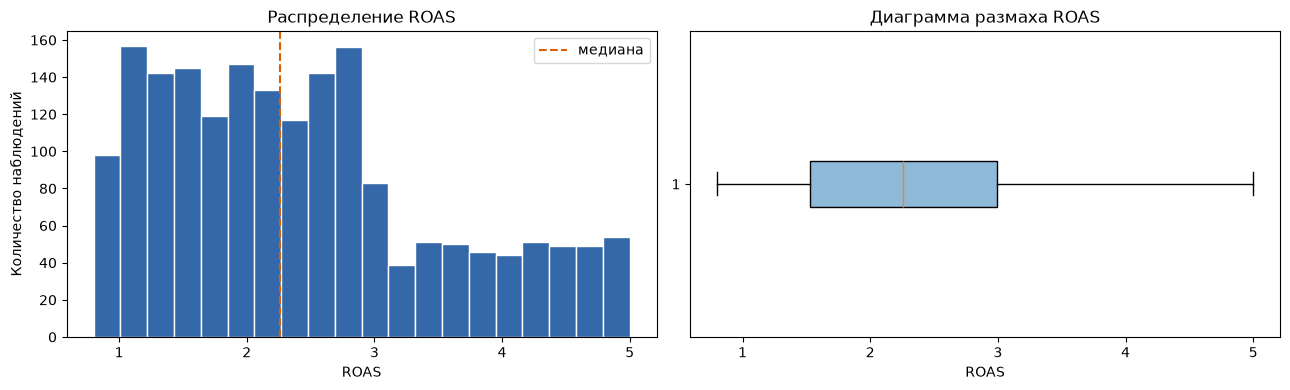

In [13]:
roas_summary = analysis_df["ROAS"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("ROAS").round(4)
roas_skew = float(stats.skew(analysis_df["ROAS"]))
roas_kurtosis = float(stats.kurtosis(analysis_df["ROAS"]))
shapiro_sample = stats.shapiro(analysis_df["ROAS"].sample(min(500, len(analysis_df)), random_state=42))
display(roas_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(analysis_df["ROAS"], bins=20, color="#3568a8", edgecolor="white")
axes[0].axvline(analysis_df["ROAS"].median(), color="#d95f02", linestyle="--", label="медиана")
axes[0].set_title("Распределение ROAS")
axes[0].set_xlabel("ROAS")
axes[0].set_ylabel("Количество наблюдений")
axes[0].legend()
axes[1].boxplot(analysis_df["ROAS"], orientation="horizontal", patch_artist=True, boxprops={"facecolor":"#8fb9d9"})
axes[1].set_title("Диаграмма размаха ROAS")
axes[1].set_xlabel("ROAS")
plt.tight_layout()
plt.show()

Средний `ROAS` равен **2,43**, медиана - **2,26**. То есть в среднем маркетинговая кампания окупается в более чем два раза. Половина наблюдений находится между **1,53** и **2,99**, а 95% значений не превышают **4,61**. Распределение имеет умеренный правый хвост: часть кампаний показывает заметно более высокую отдачу, чем основная масса.

### 2.4.2. Различия между конфигурациями кампаний

Для выявления закономерностей финансовой эффективности необходимо определить, какие характеристики рекламных кампаний связаны с более высоким ROAS. В исследовании рассматриваются четыре признака, описывающие организацию рекламы, выбор аудитории и особенности рекламных материалов.

Каждый признак имеет несколько возможных значений, которые в статистике называются уровнями признака.

| Признак | Уровни | Значение |
|---|---|---|
| Funnel - этап маркетинговой воронки | TOFU, MOFU, BOFU | TOFU - привлечение внимания потенциальных покупателей; MOFU - формирование интереса к предложению; BOFU - побуждение к покупке |
| Retargeting - стратегия повторного показа рекламы | Standard, Dynamic | Standard - повторная реклама по заранее заданным правилам; Dynamic - автоматическая адаптация рекламных материалов с учётом предыдущих действий пользователя |
| Audience - тип целевой аудитории | Custom, Lookalike 1%, Lookalike 5% | Custom - аудитория, сформированная на основе данных рекламодателя; Lookalike 1% - более узкая аудитория похожих пользователей; Lookalike 5% - более широкая аудитория с меньшей степенью сходства |
| Creative - степень персонализации рекламы | Low, High | Low - низкая степень персонализации рекламных материалов; High - высокая степень персонализации |

Сравнение этих характеристик позволяет выяснить, различается ли финансовая отдача рекламы в зависимости от выбранной стратегии и аудитории.

Поскольку каждая из 36 кампаний наблюдалась на протяжении 52 недель, сначала рассчитывается средний ROAS каждой кампании за весь период. Таким образом, при сравнении групп одна кампания учитывается как одно наблюдение, а не как 52 независимых результата.

Для статистической проверки применяется критерий Краскела-Уоллиса. Он позволяет определить, различаются ли распределения ROAS между группами, не требуя нормального распределения показателя. При уровне значимости 0,05 значение p < 0,05 рассматривается как свидетельство статистически значимых различий. 

,Признак,Уровень,Кампаний,Среднее ROAS,Медиана ROAS,Стандартное отклонение,95% ДИ среднего,H Краскела–Уоллиса,p-value
0,Funnel,BOFU,12,2.3951,2.4198,0.5954,[2.058; 2.732],0.8393,0.6573
1,Funnel,MOFU,12,2.4541,2.4751,0.5609,[2.137; 2.771],0.8393,0.6573
2,Funnel,TOFU,12,2.4480,2.3706,0.5917,[2.113; 2.783],0.8393,0.6573
3,Retargeting,Dynamic,18,2.9755,2.9286,0.1519,[2.905; 3.046],26.2703,0.0000
4,Retargeting,Standard,18,1.8893,1.8718,0.1150,[1.836; 1.942],26.2703,0.0000
5,Audience,Custom,12,2.4223,2.3962,0.5394,[2.117; 2.727],0.1096,0.9467
6,Audience,Lookalike_1%,12,2.4370,2.4587,0.5655,[2.117; 2.757],0.1096,0.9467
7,Audience,Lookalike_5%,12,2.4379,2.4198,0.6408,[2.075; 2.801],0.1096,0.9467
8,Creative,High,18,2.4186,2.4416,0.5633,[2.158; 2.679],0.1441,0.7042
9,Creative,Low,18,2.4462,2.3962,0.5859,[2.176; 2.717],0.1441,0.7042


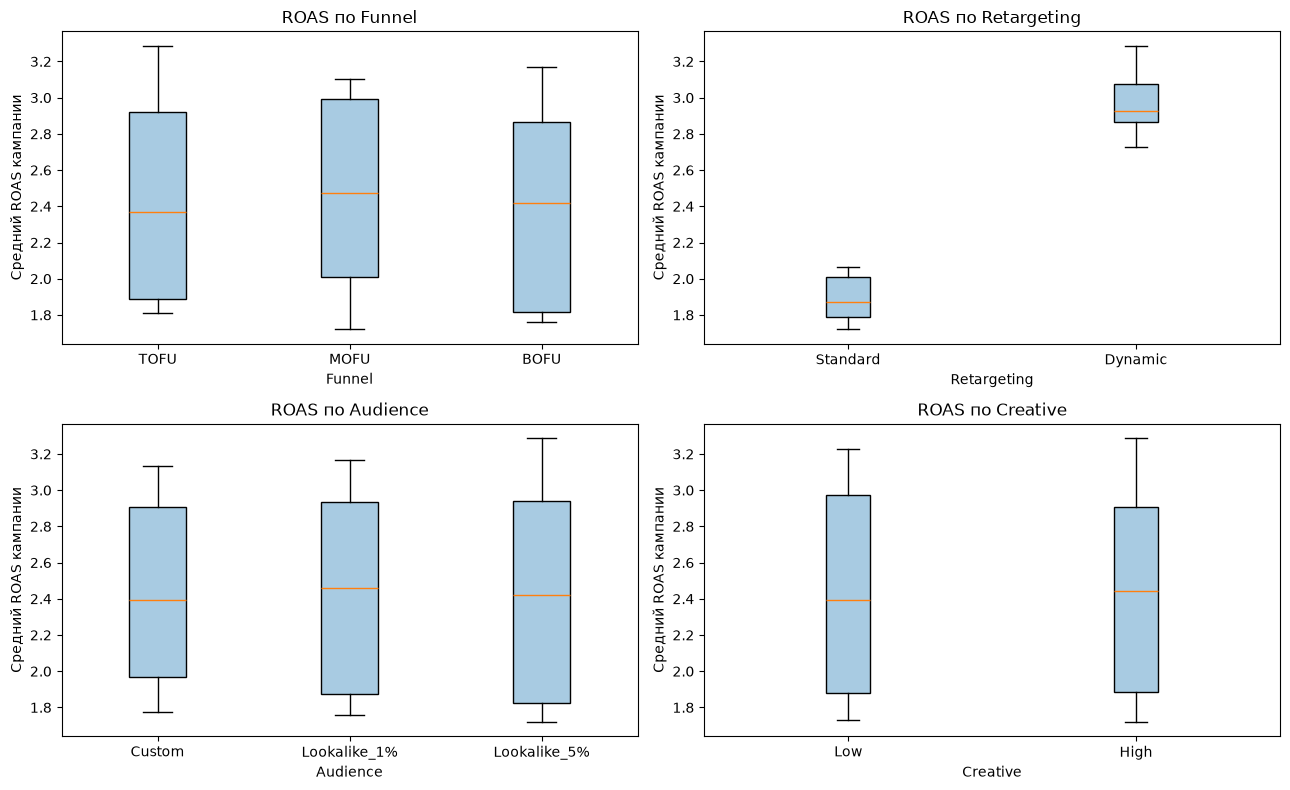

In [14]:
campaign_means = (
    analysis_df.groupby("Campaign_ID", observed=True)
    .agg({"ROAS":"mean", "Funnel":"first", "Retargeting":"first", "Audience":"first", "Creative":"first", "Audience_Size":"first"})
    .reset_index()
)

factor_rows=[]
for factor in ["Funnel", "Retargeting", "Audience", "Creative"]:
    grouped=campaign_means.groupby(factor, observed=True)["ROAS"]
    groups=[g.to_numpy() for _,g in grouped]
    kw=stats.kruskal(*groups)
    for level, values in grouped:
        factor_rows.append({
            "Признак": factor, "Уровень": level, "Кампаний": len(values),
            "Среднее ROAS": values.mean(), "Медиана ROAS": values.median(),
            "Стандартное отклонение": values.std(ddof=1),
            "95% ДИ среднего": f"[{values.mean()-1.96*values.std(ddof=1)/np.sqrt(len(values)):.3f}; {values.mean()+1.96*values.std(ddof=1)/np.sqrt(len(values)):.3f}]",
            "H Краскела–Уоллиса": kw.statistic, "p-value": kw.pvalue,
        })
group_results=pd.DataFrame(factor_rows)
display(group_results.round(4))

fig, axes=plt.subplots(2,2,figsize=(13,8))
for ax, factor in zip(axes.ravel(), ["Funnel","Retargeting","Audience","Creative"]):
    levels=list(campaign_means[factor].dropna().unique())
    data=[campaign_means.loc[campaign_means[factor].eq(level),"ROAS"] for level in levels]
    ax.boxplot(data, tick_labels=[str(x) for x in levels], patch_artist=True, boxprops={"facecolor":"#a8cbe2"})
    ax.set_title(f"ROAS по {factor}")
    ax.set_xlabel(factor); ax.set_ylabel("Средний ROAS кампании")
plt.tight_layout(); plt.show()

Сравнение финансовой эффективности рекламных кампаний показало, что наиболее выраженные различия ROAS наблюдаются между стратегиями ретаргетинга. Кампании с динамическим ретаргетингом имеют средний ROAS 2,98, тогда как со стандартным ретаргетингом этот показатель составляет 1,89. Разница достигает 1,09 пункта ROAS, что соответствует примерно 57% относительно стандартного ретаргетинга. Таким образом, в исследуемом наборе динамическая стратегия связана с заметно более высокой финансовой отдачей рекламных расходов.

Критерий Краскела-Уоллиса подтвердил статистическую значимость обнаруженных различий: H = 26,27, p < 0,001. При этом сравнение кампаний по этапам маркетинговой воронки, типам целевой аудитории и степени персонализации рекламных материалов не выявило статистически значимых различий ROAS. Это означает, что в рассматриваемых данных именно стратегия ретаргетинга наиболее отчётливо связана с финансовой эффективностью рекламы.

Однако статистическая значимость не доказывает, что применение динамического ретаргетинга само по себе приводит к увеличению ROAS. На результат могут влиять и другие особенности кампаний. Поэтому обнаруженную закономерность следует рассматривать как основание для дальнейшего анализа и потенциального пересмотра распределения рекламного бюджета.

### 2.4.3. Недельная динамика и внешний контекст

Помимо характеристик самих рекламных кампаний, на их эффективность могут быть связаны с изменениями внешней среды. Поэтому необходимо проверить, как ROAS менялся в течение исследуемого периода и совпадали ли его колебания с изменениями интереса к кофейной тематике.

Для каждой из 52 недель рассчитывается средний ROAS по 36 кампаниям. Это позволяет оценить общую динамику финансовой эффективности рекламы, выявить периоды роста и снижения показателя и проверить наличие устойчивой тенденции.

Дополнительно недельный ROAS сопоставляется с показателями трёх внешних источников: Wikimedia характеризует интерес пользователей к кофейной тематике, Daily Coffee News - активность отраслевых публикаций, а CoffeeReview - интенсивность выхода обзоров.

Для оценки взаимосвязей используется коэффициент корреляции Спирмена. Он показывает направление и силу статистической связи между двумя показателями: положительное значение соответствует их совместному увеличению, отрицательное — противоположному изменению. Значения, близкие к нулю, указывают на отсутствие выраженной монотонной связи.

Такой анализ позволит определить, сопровождаются ли изменения финансовой эффективности рекламы изменениями внешнего информационного фона и заслуживают ли эти факторы дальнейшего изучения.

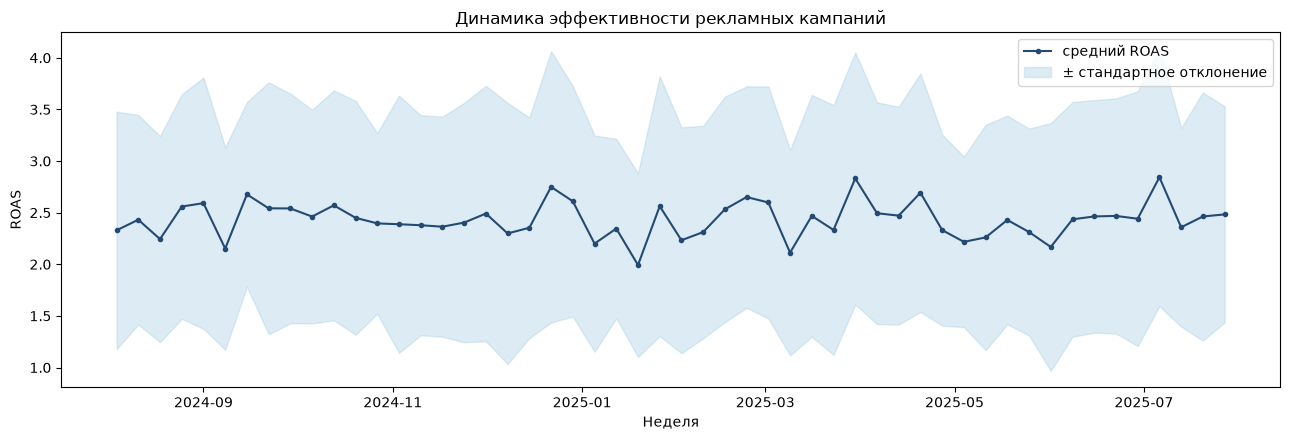

,Коэффициент Спирмена: неделя и средний ROAS,p-value,Минимальный средний ROAS,Максимальный средний ROAS
0,-0.0118,0.9339,1.9925,2.8428


,Признак,Коэффициент Спирмена,p-value
8,review_unique_authors,0.2081,0.1389
5,news_unique_authors,-0.1367,0.3338
4,news_count,0.1047,0.4600
2,wiki_daily_views_std,0.0578,0.6840
6,news_text_chars,0.0480,0.7355
3,wiki_weekend_share,0.0192,0.8925
7,review_count,0.0172,0.9037
9,review_text_chars,0.0154,0.9138
0,wiki_views,0.0051,0.9712
1,wiki_peak_daily_views,0.0018,0.9899


In [15]:
weekly_summary = analysis_df.groupby("Date", as_index=False).agg(
    ROAS_mean=("ROAS", "mean"), ROAS_median=("ROAS", "median"), ROAS_std=("ROAS", "std"),
    campaign_count=("Campaign_ID", "nunique"),
)
weekly_context = analysis_df[["Date"]+external_columns].drop_duplicates("Date")
weekly_summary = weekly_summary.merge(weekly_context, on="Date", validate="one_to_one")

fig, ax = plt.subplots(figsize=(13,4.5))
ax.plot(weekly_summary["Date"], weekly_summary["ROAS_mean"], color="#244a73", marker="o", markersize=3, label="средний ROAS")
ax.fill_between(weekly_summary["Date"], weekly_summary["ROAS_mean"]-weekly_summary["ROAS_std"], weekly_summary["ROAS_mean"]+weekly_summary["ROAS_std"], color="#9ecae1", alpha=.35, label="± стандартное отклонение")
ax.set_title("Динамика эффективности рекламных кампаний")
ax.set_xlabel("Неделя"); ax.set_ylabel("ROAS"); ax.legend(); plt.tight_layout(); plt.show()

def corr_table(cols):
 rows=[]
 for c in cols:
  r=stats.spearmanr(weekly_summary[c], weekly_summary["ROAS_mean"])
  rows.append({"Признак":c,"Коэффициент Спирмена":r.statistic,"p-value":r.pvalue})
 return pd.DataFrame(rows).sort_values("p-value")
context_correlations=corr_table(external_columns)
trend_test=stats.spearmanr(np.arange(len(weekly_summary)), weekly_summary["ROAS_mean"])
dynamics_table=pd.DataFrame([{"Коэффициент Спирмена: неделя и средний ROAS":trend_test.statistic,"p-value":trend_test.pvalue,"Минимальный средний ROAS":weekly_summary["ROAS_mean"].min(),"Максимальный средний ROAS":weekly_summary["ROAS_mean"].max()}])
display(dynamics_table.round(4))
display(context_correlations.round(4))


Средний недельный ROAS изменялся от 1,99 до 2,84, однако устойчивой тенденции к росту или снижению за исследуемый период не обнаружено. Коэффициент корреляции Спирмена между номером недели и средним ROAS составил -0,012 при p = 0,934, что не позволяет говорить о статистически значимом временном тренде.

Сопоставление с внешними источниками также не выявило статистически значимых связей. Наибольшая положительная корреляция получена для числа авторов обзоров CoffeeReview (0,208), однако её статистическая значимость недостаточна (p = 0,139). Для остальных показателей связи оказались ещё слабее.

Таким образом, недельные колебания ROAS не демонстрируют выраженной связи с исследуемыми внешними показателями. Вместе с тем корреляционный анализ оценивает только отдельные связи за один и тот же период. Поэтому далее будет проверено, могут ли внешние показатели предыдущих недель повышать точность прогнозирования ROAS.



### 2.4.4. Проверка гипотезы с учётом повторных наблюдений

Финансовая эффективность кампаний может одновременно зависеть от разных характеристик и изменяться от недели к неделе. Поэтому необходимо проверить, сохраняется ли обнаруженная связь при совместном учёте этих факторов.

Для этого используется регрессионная модель, в которой ROAS сопоставляется с этапом маркетинговой воронки, типом ретаргетинга, аудиторией, степенью персонализации рекламы и размером аудитории. Дополнительно учитываются различия между неделями.

Поскольку каждая кампания наблюдается 52 раза, расчёт статистической значимости учитывает зависимость наблюдений внутри одной кампании. Также проверяются сочетания характеристик: зависит ли результат определённого типа аудитории от этапа воронки и меняется ли связь ретаргетинга с ROAS при разной степени персонализации рекламы.

In [16]:
within_variance = analysis_df.assign(campaign_mean=analysis_df.groupby("Campaign_ID", observed=True)["ROAS"].transform("mean")).groupby("Campaign_ID", observed=True)["ROAS"].var().mean()
between_variance = campaign_means["ROAS"].var(ddof=1)
lag_values=[]
for _, g in analysis_df.groupby("Campaign_ID", observed=True):
    lag_values.append(g.sort_values("Date")["ROAS"].autocorr(1))
panel_diagnostics=pd.DataFrame([{
    "Средняя внутрикaмпанийная дисперсия": within_variance,
    "Дисперсия средних кампаний": between_variance,
    "Доля межкампанийной вариации": between_variance/(between_variance+within_variance),
    "Средняя автокорреляция соседних недель": np.nanmean(lag_values),
}])
display(panel_diagnostics.round(4))

formula_main="ROAS ~ C(Funnel) + C(Retargeting) + C(Audience) + C(Creative) + Audience_Size + C(Date)"
main_panel_model=smf.ols(formula_main, data=analysis_df).fit(cov_type="cluster", cov_kwds={"groups":analysis_df["Campaign_ID"]})
main_terms=[x for x in main_panel_model.params.index if not x.startswith("C(Date)")]
display(pd.DataFrame({"коэффициент":main_panel_model.params[main_terms],"p-value":main_panel_model.pvalues[main_terms],"нижняя граница ДИ":main_panel_model.conf_int().loc[main_terms,0],"верхняя граница ДИ":main_panel_model.conf_int().loc[main_terms,1]}).round(4))

interaction_formula="ROAS ~ C(Funnel)*C(Audience) + C(Retargeting)*C(Creative) + Audience_Size + C(Date)"
interaction_model=smf.ols(interaction_formula, data=analysis_df).fit(cov_type="cluster", cov_kwds={"groups":analysis_df["Campaign_ID"]})
interaction_terms=[x for x in interaction_model.params.index if "]:C(" in x]
interaction_table=pd.DataFrame({"коэффициент":interaction_model.params[interaction_terms],"p-value":interaction_model.pvalues[interaction_terms],"нижняя граница ДИ":interaction_model.conf_int().loc[interaction_terms,0],"верхняя граница ДИ":interaction_model.conf_int().loc[interaction_terms,1]})
display(interaction_table.round(4))

,Средняя внутрикaмпанийная дисперсия,Дисперсия средних кампаний,Доля межкампанийной вариации,Средняя автокорреляция соседних недель
0,0.9102,0.321,0.2607,0.018


,коэффициент,p-value,нижняя граница ДИ,верхняя граница ДИ
Intercept,2.7439,0.0000,2.3113,3.1765
C(Funnel)[T.MOFU],0.0592,0.2159,-0.0345,0.1529
C(Funnel)[T.TOFU],0.0533,0.3369,-0.0555,0.1622
C(Retargeting)[T.Standard],-1.0863,0.0000,-1.1718,-1.0007
C(Audience)[T.Lookalike_1%],0.0135,0.7758,-0.0794,0.1064
C(Audience)[T.Lookalike_5%],0.0156,0.7899,-0.0993,0.1305
C(Creative)[T.Low],0.0268,0.5364,-0.0581,0.1116
Audience_Size,0.0001,0.6731,-0.0002,0.0003


,коэффициент,p-value,нижняя граница ДИ,верхняя граница ДИ
C(Funnel)[T.MOFU]:C(Audience)[T.Lookalike_1%],0.0024,0.9806,-0.1947,0.1996
C(Funnel)[T.TOFU]:C(Audience)[T.Lookalike_1%],-0.0410,0.7111,-0.2581,0.1760
C(Funnel)[T.MOFU]:C(Audience)[T.Lookalike_5%],-0.1202,0.2581,-0.3285,0.0881
C(Funnel)[T.TOFU]:C(Audience)[T.Lookalike_5%],0.1812,0.1733,-0.0796,0.4421
C(Retargeting)[T.Standard]:C(Creative)[T.Low],-0.0384,0.6096,-0.1857,0.1089



Регрессионный анализ подтвердил, что наиболее выраженная связь с ROAS наблюдается для стратегии ретаргетинга. При учёте других характеристик кампаний и недельных различий ROAS стандартного ретаргетинга в среднем ниже динамического на 1,09 пункта. Различие статистически значимо (p < 0,001; 95% доверительный интервал от −1,17 до −1,00).

Для этапа маркетинговой воронки, типа аудитории, персонализации рекламы и размера аудитории значимых самостоятельных связей не обнаружено. Проверка сочетаний характеристик также не выявила убедительных различий: нет оснований утверждать, что эффективность выбранной аудитории зависит от этапа воронки или что преимущество динамического ретаргетинга существенно меняется в зависимости от персонализации рекламы.

Таким образом, связь стратегии ретаргетинга с финансовой эффективностью сохраняется даже при учёте остальных исследуемых факторов. 


### 2.4.5. Временное разделение для прогноза

Следующей задачей является проверка того, насколько точно можно предсказать ROAS рекламной кампании по её характеристикам и внешнему контексту. Здесь оценивается способность модели прогнозировать результаты будущих недель.

Для обучения используются первые 42 недели (1512 наблюдений), а для проверки - последние 10 недель (360 наблюдений). Такое разделение воспроизводит практическую ситуацию: прогноз строится на основе прошлого и оценивается на более поздних данных.

В модель включаются характеристики кампаний, размер аудитории и порядковый номер недели. Показатели CTR, Conversions, Spend и сам ROAS не используются в качестве входных данных, поскольку задача состоит в прогнозировании ROAS без привлечения показателей уже полученного рекламного результата.

Внешние показатели Wikimedia, Daily Coffee News и CoffeeReview берутся за предыдущую неделю. Это позволяет проверить, помогает ли ранее наблюдавшийся информационный фон прогнозировать эффективность рекламы, не используя сведения из прогнозируемой недели.

Такое разделение обеспечивает сопоставимую проверку моделей с внешними данными и без них.

In [17]:
# лаги строятся на недельной таблице до разделения на обучение и проверку
weekly_features = analysis_df[["Date"] + external_columns].drop_duplicates("Date").sort_values("Date").copy()
for c in external_columns:
    weekly_features[f"{c}_lag1"] = weekly_features[c].shift(1)
model_df = analysis_df.drop(columns=[c for c in analysis_df.columns if c.endswith("_lag1")], errors="ignore").merge(
    weekly_features[["Date"] + [f"{c}_lag1" for c in external_columns]],
    on="Date", how="left", validate="many_to_one"
)
unique_dates=np.array(sorted(model_df["Date"].unique()))
train_dates=unique_dates[:42]; test_dates=unique_dates[42:]
train_df=model_df[model_df["Date"].isin(train_dates)].copy()
test_df=model_df[model_df["Date"].isin(test_dates)].copy()

categorical_features=["Funnel","Retargeting","Audience","Creative"]
base_numeric=["Audience_Size","week_index"]
feature_groups={"Wikimedia":[f"{c}_lag1" for c in external_groups["Wikimedia"]],"Daily Coffee News":[f"{c}_lag1" for c in external_groups["Daily Coffee News"]],"CoffeeReview":[f"{c}_lag1" for c in external_groups["CoffeeReview"]]}
base_features=categorical_features+base_numeric

display(pd.DataFrame([{
    "Обучение": f"{len(train_dates)} недель / {len(train_df)} строк, до {train_dates[-1].date()}",
    "Проверка": f"{len(test_dates)} недель / {len(test_df)} строк, с {test_dates[0].date()}"
}]))

,Обучение,Проверка
0,"42 недель / 1512 строк, до 2025-05-18","10 недель / 360 строк, с 2025-05-25"


### 2.4.6. Сравнение моделей

Для прогнозирования ROAS используются три подхода, различающиеся способом формирования прогноза.

Простейший подход - прогноз средним значением ROAS за период обучения. Он не учитывает особенности отдельных кампаний и нужен для проверки того, дают ли более сложные методы реальное улучшение.

Ridge - метод линейной регрессии. Он определяет, как характеристики кампании связаны с ROAS, присваивая каждой из них числовой коэффициент. Прогноз рассчитывается как сумма этих вкладов и свободного коэффициента. Например, модель может учитывать, как меняется ожидаемый ROAS при выборе другого типа ретаргетинга или аудитории. Особенность Ridge - ограничение величины коэффициентов, которое помогает уменьшить переобучение и повысить устойчивость прогноза.

Random Forest (случайный лес) строит множество деревьев решений. Каждое дерево последовательно разделяет кампании на группы по их характеристикам и формирует собственный прогноз ROAS. Итоговое значение определяется усреднением прогнозов всех деревьев. В отличие от Ridge, этот метод способен учитывать нелинейные зависимости и сложные сочетания признаков.

Сначала модели обучаются только на характеристиках рекламных кампаний, затем к ним по отдельности добавляются показатели Wikimedia, Daily Coffee News и CoffeeReview. Также проверяется совместное использование всех внешних источников. Это позволяет установить, улучшают ли внешние данные прогноз по сравнению с использованием только характеристик рекламы.

Точность оценивается по трём показателям: MAE - средняя абсолютная величина ошибки прогноза; RMSE - показатель, сильнее учитывающий крупные ошибки; R2 - насколько хорошо прогноз объясняет изменчивость ROAS по сравнению с прогнозом средним значением. Чем ниже MAE и RMSE и выше R2, тем качественнее модель.

In [18]:
def make_pipeline(features, estimator):
    cats=[c for c in features if c in categorical_features]
    nums=[c for c in features if c not in cats]
    pre=ColumnTransformer([
        ("categories", Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))]), cats),
        ("numeric", Pipeline([("imputer",SimpleImputer(strategy="median")),("scale",StandardScaler())]), nums),
    ])
    return Pipeline([("preprocessor",pre),("model",estimator)])

def metrics_for(name, features, estimator):
    pipeline=make_pipeline(features, estimator)
    pipeline.fit(train_df[features], train_df["ROAS"])
    pred=pipeline.predict(test_df[features])
    return {"Модель":name,"Признаков":len(features),"MAE":mean_absolute_error(test_df["ROAS"],pred),"RMSE":mean_squared_error(test_df["ROAS"],pred)**0.5,"R2":r2_score(test_df["ROAS"],pred)}

train_mean=train_df["ROAS"].mean()
baseline_pred=np.full(len(test_df),train_mean)
model_rows=[{"Модель":"Базовый прогноз средним","Признаков":0,"MAE":mean_absolute_error(test_df["ROAS"],baseline_pred),"RMSE":mean_squared_error(test_df["ROAS"],baseline_pred)**0.5,"R2":r2_score(test_df["ROAS"],baseline_pred)}]
source_features={"Только характеристики кампании":base_features}
for group, cols in feature_groups.items(): source_features[f"Кампания + {group}"]=base_features+cols
source_features["Кампания + весь внешний контекст"]=base_features+sum(feature_groups.values(),[])

for label, features in source_features.items():
    model_rows.append(metrics_for("Ridge: "+label,features,Ridge(alpha=1.0)))
for label in ["Только характеристики кампании","Кампания + весь внешний контекст"]:
    model_rows.append(metrics_for("Random Forest: "+label,source_features[label],RandomForestRegressor(n_estimators=300,min_samples_leaf=5,max_features=0.8,random_state=42,n_jobs=-1)))
model_results=pd.DataFrame(model_rows)
display(model_results.round(4))

ridge_base=metrics_for("Ridge: кампания-only",base_features,Ridge(alpha=1.0))
ridge_all=metrics_for("Ridge: кампания + внешние факторы",source_features["Кампания + весь внешний контекст"],Ridge(alpha=1.0))

,Модель,Признаков,MAE,RMSE,R2
0,Базовый прогноз средним,0,0.9198,1.1291,-0.0001
1,Ridge: Только характеристики кампании,6,0.8392,0.9979,0.2188
2,Ridge: Кампания + Wikimedia,10,0.8417,0.9989,0.2172
3,Ridge: Кампания + Daily Coffee News,9,0.8444,1.0110,0.1981
4,Ridge: Кампания + CoffeeReview,9,0.8378,0.9972,0.2199
5,Ridge: Кампания + весь внешний контекст,16,0.8469,1.0114,0.1976
6,Random Forest: Только характеристики кампании,6,0.8591,1.0458,0.1421
7,Random Forest: Кампания + весь внешний контекст,16,0.8607,1.0247,0.1763



Все обученные модели показали более высокую точность, чем простой прогноз средним значением. Наилучший результат среди моделей, использующих только характеристики кампаний, получен методом Ridge: средняя абсолютная ошибка снизилась с 0,920 до 0,839, а R2 достиг 0,219. Случайный лес оказался менее точным (MAE = 0,859), поэтому усложнение модели не привело к улучшению прогноза.

Добавление данных CoffeeReview незначительно снизило ошибку Ridge до 0,838, однако улучшение слишком мало для уверенного вывода о пользе этого источника. Показатели Wikimedia и Daily Coffee News по отдельности ухудшили точность, а совместное использование всех внешних источников увеличило MAE до 0,847.

Таким образом, наиболее целесообразной моделью пока является Ridge на основе характеристик рекламных кампаний. Результаты подтверждают их практическую значимость для прогнозирования ROAS, тогда как устойчивой дополнительной пользы внешнего контекста на данном этапе не обнаружено.


### 2.4.7. Устойчивость результата на последовательных периодах

Оценка модели на одном проверочном периоде может зависеть от особенностей выбранных недель. Поэтому необходимо проверить, сохраняется ли точность прогноза на разных участках исследуемого периода.

Для этого применяется последовательная проверка по времени. Сначала модель Ridge обучается на первых 32 неделях и прогнозирует ROAS следующих пяти недель. Затем обучающий период расширяется до 37, 42 и 47 недель, после чего каждый раз проверяется прогноз на следующих пяти неделях. Таким образом, модель четыре раза оценивается на новых данных, не используя информацию из будущего.

На каждом этапе сравниваются два варианта Ridge: только с характеристиками рекламных кампаний и с добавлением всех внешних показателей, что позволяет определить, дают ли Wikimedia, Daily Coffee News и CoffeeReview устойчивое улучшение прогноза, а не случайный выигрыш на отдельных неделях.

In [19]:
cv_rows=[]
for fold,(tr_idx,va_idx) in enumerate(TimeSeriesSplit(n_splits=4,test_size=5).split(unique_dates),1):
    tr_dates=unique_dates[tr_idx]; va_dates=unique_dates[va_idx]
    tr=model_df[model_df["Date"].isin(tr_dates)]; va=model_df[model_df["Date"].isin(va_dates)]
    row={"Разрез":fold,"Обучение недель":len(tr_dates),"Проверка недель":len(va_dates)}
    for label, features in [("Кампания-only",base_features),("Кампания + весь контекст",source_features["Кампания + весь внешний контекст"])]:
        p=make_pipeline(features,Ridge(alpha=1.0)); p.fit(tr[features],tr["ROAS"]); pred=p.predict(va[features])
        row[f"{label}: MAE"]=mean_absolute_error(va["ROAS"],pred)
        row[f"{label}: RMSE"]=mean_squared_error(va["ROAS"],pred)**0.5
        row[f"{label}: R²"]=r2_score(va["ROAS"],pred)
    cv_rows.append(row)
cv_results=pd.DataFrame(cv_rows)
display(cv_results.round(4))
display(cv_results[["Кампания-only: MAE","Кампания + весь контекст: MAE"]].mean().to_frame("среднее MAE").round(4))

,Разрез,Обучение недель,Проверка недель,Кампания-only: MAE,Кампания-only: RMSE,Кампания-only: R²,Кампания + весь контекст: MAE,Кампания + весь контекст: RMSE,Кампания + весь контекст: R²
0,1,32,5,0.8170,0.9805,0.2655,0.8065,0.9766,0.2713
1,2,37,5,0.7613,0.9292,0.1513,0.7722,0.9383,0.1347
2,3,42,5,0.8523,1.0020,0.1894,0.8582,1.0211,0.1582
3,4,47,5,0.8275,0.9967,0.2359,0.8300,0.9999,0.2310


,среднее MAE
Кампания-only: MAE,0.8145
Кампания + весь контекст: MAE,0.8167



На четырёх последовательных проверках средняя абсолютная ошибка Ridge с характеристиками кампаний составила 0,815, а с добавлением внешних показателей - 0,817. Внешний контекст немного улучшил прогноз на первых двух периодах, но ухудшил на последних двух.

Таким образом, добавление внешних данных не обеспечивает устойчивого повышения точности. Для дальнейшего использования предпочтительна более простая модель Ridge, основанная на характеристиках рекламных кампаний. Внешние показатели целесообразно сохранить для описательного анализа, но не включать в основную прогнозную модель.


### 2.4.8. Парное сравнение стратегий ретаргетинга

Ретаргетинг - это повторный показ рекламы пользователям, которые ранее взаимодействовали с брендом или его предложением. 
Стандартный ретаргетинг (Standard) использует заранее определённые аудитории и правила показа, тогда как динамический (Dynamic) предполагает адаптацию рекламного содержания к интересам и предыдущим действиям пользователя.

Предыдущий анализ выявил преимущество динамического ретаргетинга по ROAS. Чтобы проверить, сохраняется ли оно при одинаковых условиях, проводится парное сравнение кампаний. В каждую пару входят две кампании с одинаковыми этапом маркетинговой воронки, типом аудитории и уровнем персонализации рекламы, но разными стратегиями ретаргетинга. Кроме того, результаты сравниваются за одни и те же недели.

Всего сформировано 18 пар, каждая из которых наблюдается на протяжении 52 недель. Для статистической проверки сначала рассчитывается средняя разница ROAS внутри каждой пары за весь период, что позволяет избежать ошибочного представления повторных недельных наблюдений как независимых кампаний.

Для проверки различий используются парный критерий Стьюдента, оценивающий значимость средней разницы, и критерий Уилкоксона, основанный на рангах парных различий. Дополнительно рассчитывается 95% доверительный интервал методом повторной выборки и размер эффекта, характеризующий выраженность различий относительно их разброса.

,Средняя разница,95% ДИ,p-value парного t-теста,p-value Уилкоксона,Размер эффекта d_z,Положительных пар,Всего пар
0,1.0863,[1.001; 1.176],1.79e-14,7.63e-06,5.5942,18,18


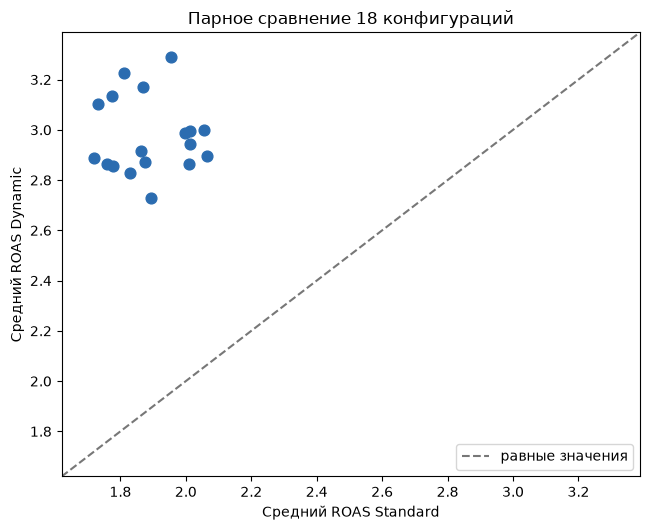

In [20]:
# Формирование пар: одинаковые Funnel, Audience и Creative, разные стратегии ретаргетинга.
pair_keys = ["Funnel", "Audience", "Creative"]
pair_wide = analysis_df.pivot_table(
    index=pair_keys + ["Date"], columns="Retargeting",
    values=["ROAS", "Spend", "Audience_Size"], aggfunc="first"
)
pair_wide.columns = [f"{metric}_{strategy}" for metric, strategy in pair_wide.columns]
pair_wide = pair_wide.reset_index()
required_pair_columns = [
    "ROAS_Dynamic", "ROAS_Standard", "Spend_Dynamic", "Spend_Standard",
    "Audience_Size_Dynamic", "Audience_Size_Standard",
]
missing_pair_columns = [c for c in required_pair_columns if c not in pair_wide.columns]
if missing_pair_columns:
    raise ValueError(f"Не удалось сформировать полные пары кампаний: {missing_pair_columns}")

pair_wide["pair_id"] = pair_wide[pair_keys].astype(str).agg(" | ".join, axis=1)
pair_wide["ROAS_difference"] = pair_wide["ROAS_Dynamic"] - pair_wide["ROAS_Standard"]
pair_wide["Spend_difference"] = pair_wide["Spend_Dynamic"] - pair_wide["Spend_Standard"]
pair_wide["Audience_Size_difference"] = pair_wide["Audience_Size_Dynamic"] - pair_wide["Audience_Size_Standard"]
pair_wide["mean_spend"] = (pair_wide["Spend_Dynamic"] + pair_wide["Spend_Standard"]) / 2

expected_pair_weeks = pair_wide["pair_id"].nunique() * pair_wide["Date"].nunique()
if len(pair_wide) != expected_pair_weeks:
    raise ValueError("Временное покрытие сопоставимых конфигураций неполное")

pair_means = (
    pair_wide.groupby("pair_id", observed=True)
    .agg(
        Dynamic_ROAS=("ROAS_Dynamic", "mean"),
        Standard_ROAS=("ROAS_Standard", "mean"),
        ROAS_difference=("ROAS_difference", "mean"),
        Spend_difference=("Spend_difference", "mean"),
        Audience_Size_difference=("Audience_Size_difference", "mean"),
        Funnel=("Funnel", "first"), Audience=("Audience", "first"), Creative=("Creative", "first"),
    )
    .reset_index()
)

def paired_statistics(values, seed=42, n_boot=20_000):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    bootstrap_means = rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    t_result = stats.ttest_1samp(values, 0)
    w_result = stats.wilcoxon(values, zero_method="wilcox")
    return {
        "Средняя разница": values.mean(),
        "95% ДИ": f"[{np.quantile(bootstrap_means, .025):.3f}; {np.quantile(bootstrap_means, .975):.3f}]",
        "p-value парного t-теста": f"{t_result.pvalue:.2e}",
        "p-value Уилкоксона": f"{w_result.pvalue:.2e}",
        "Размер эффекта d_z": values.mean() / values.std(ddof=1),
        "Положительных пар": int((values > 0).sum()),
        "Всего пар": len(values),
    }

pair_effect = pd.DataFrame([paired_statistics(pair_means["ROAS_difference"])])
display(pair_effect.round(4))

# График показывает средние ROAS в 18 сопоставимых конфигурациях.
fig, ax = plt.subplots(figsize=(6.6, 5.4))
lo = min(pair_means["Standard_ROAS"].min(), pair_means["Dynamic_ROAS"].min()) - .1
hi = max(pair_means["Standard_ROAS"].max(), pair_means["Dynamic_ROAS"].max()) + .1
ax.scatter(pair_means["Standard_ROAS"], pair_means["Dynamic_ROAS"], color="#2b6cb0", s=60)
ax.plot([lo, hi], [lo, hi], linestyle="--", color="#777777", label="равные значения")
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel("Средний ROAS Standard"); ax.set_ylabel("Средний ROAS Dynamic")
ax.set_title("Парное сравнение 18 конфигураций"); ax.legend()
plt.tight_layout(); plt.show()


Парное сравнение показало, что во всех 18 сопоставимых конфигурациях средний ROAS динамического ретаргетинга выше, чем стандартного. Средняя разница составляет 1,086 пункта ROAS, а 95% доверительный интервал находится в пределах от 1,001 до 1,176. Оба статистических критерия подтверждают значимость различий (p < 0,001).

На графике каждая точка соответствует одной паре кампаний. Пунктирная линия обозначает одинаковую эффективность двух стратегий. Все точки расположены выше неё, что наглядно подтверждает преимущество динамического ретаргетинга во всех исследуемых конфигурациях.

Таким образом, обнаруженное различие сохраняется при одинаковых настройках воронки, аудитории и персонализации рекламы.


### 2.4.9. Проверка устойчивости преимущества динамического ретаргетинга

Парное сравнение показало более высокий ROAS динамического ретаргетинга. Однако для практического применения важно установить, сохраняется ли это преимущество в разных условиях или оно характерно только для отдельных групп кампаний.

Сначала сравнивается разница ROAS между динамичным и стандартным ретаргетингом для каждого этапа маркетинговой воронки, типа аудитории и уровня персонализации рекламы. Затем проверяется устойчивость результата во времени: исследуемый год делится на две половины по 26 недель, а также рассматривается еженедельное изменение разницы между стратегиями.

Отдельно анализируются расходы на рекламу и размер аудитории. Эти показатели могут влиять на эффективность кампаний, поэтому необходимо проверить, различаются ли они между сопоставимыми парами и сохраняется ли преимущество Dynamic после их учёта. Для этого используется регрессионная модель, учитывающая особенности каждой пары кампаний и общие различия между неделями.

Такой анализ позволяет определить, насколько широко воспроизводится обнаруженная закономерность и не связана ли она с другими наблюдаемыми характеристиками рекламы.

,Сегмент,Уровень,Средняя разница,95% ДИ,Положительных пар,Всего пар
0,Funnel,BOFU,1.1156,[0.980; 1.253],6,6
1,Funnel,MOFU,1.0491,[0.922; 1.202],6,6
2,Funnel,TOFU,1.0941,[0.935; 1.268],6,6
3,Audience,Custom,1.0052,[0.877; 1.164],6,6
4,Audience,Lookalike_1%,1.0634,[0.985; 1.166],6,6
5,Audience,Lookalike_5%,1.1902,[1.016; 1.347],6,6
6,Creative,High,1.0668,[0.996; 1.151],9,9
7,Creative,Low,1.1058,[0.950; 1.263],9,9


,Период,Средняя разница,95% ДИ,Положительных пар,Всего пар
0,Первые 26 недель,1.0953,[0.989; 1.202],18,18
1,Последние 26 недель,1.0773,[0.958; 1.199],18,18


,Проверка,Оценка,95% ДИ,p-value
0,Разница расходов: Dynamic - Standard,-4.8666,[-11.548; 2.209],1.97e-01
1,Разница размера аудитории: Dynamic - Standard,-0.3718,[-20.150; 20.117],9.72e-01
2,"Dynamic после учёта даты, пары и Audience_Size",1.0863,[0.995; 1.177],1.20e-120
3,Изменение преимущества Dynamic при росте Spend,-0.0005,[-0.00170; 0.00073],4.38e-01


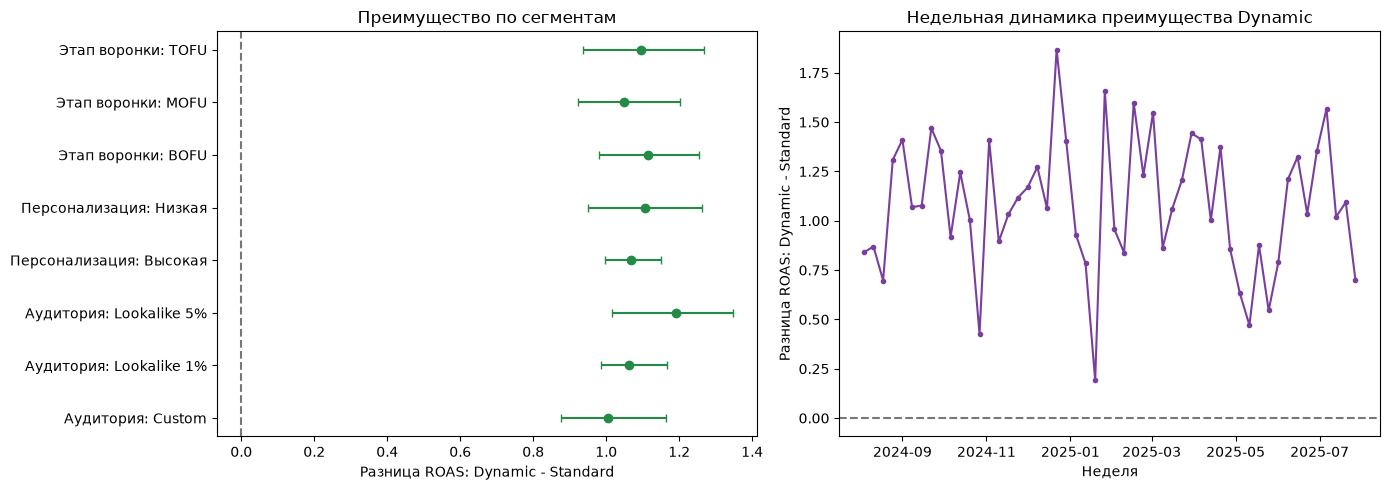

In [21]:
segment_rows = []
for factor in ["Funnel", "Audience", "Creative"]:
    for level, group in pair_means.groupby(factor, observed=True):
        item = paired_statistics(group["ROAS_difference"], seed=42)
        item.update({"Сегмент": factor, "Уровень": level})
        segment_rows.append(item)
segment_effects = pd.DataFrame(segment_rows)
display(segment_effects[["Сегмент", "Уровень", "Средняя разница", "95% ДИ", "Положительных пар", "Всего пар"]].round(4))

ordered_dates = np.sort(pair_wide["Date"].unique())
period_rows = []
for label, date_subset in [("Первые 26 недель", ordered_dates[:26]), ("Последние 26 недель", ordered_dates[26:])]:
    values = pair_wide.loc[pair_wide["Date"].isin(date_subset)].groupby("pair_id", observed=True)["ROAS_difference"].mean()
    item = paired_statistics(values, seed=42)
    item["Период"] = label
    period_rows.append(item)
period_effects = pd.DataFrame(period_rows)
display(period_effects[["Период", "Средняя разница", "95% ДИ", "Положительных пар", "Всего пар"]].round(4))

spend_check = paired_statistics(pair_means["Spend_difference"], seed=42)
audience_check = paired_statistics(pair_means["Audience_Size_difference"], seed=42)
long_pairs = analysis_df.copy()
long_pairs["pair_id"] = long_pairs[pair_keys].astype(str).agg(" | ".join, axis=1)
long_pairs["is_dynamic"] = long_pairs["Retargeting"].eq("Dynamic").astype(int)
control_model = smf.ols(
    "ROAS ~ is_dynamic + Audience_Size + C(Date) + C(pair_id)", data=long_pairs
).fit(cov_type="cluster", cov_kwds={"groups": long_pairs["pair_id"]})
spend_interaction_model = smf.ols(
    "ROAS ~ is_dynamic * Spend + Audience_Size + C(Date) + C(pair_id)", data=long_pairs
).fit(cov_type="cluster", cov_kwds={"groups": long_pairs["pair_id"]})
control_ci = control_model.conf_int().loc["is_dynamic"]
interaction_ci = spend_interaction_model.conf_int().loc["is_dynamic:Spend"]
controls_table = pd.DataFrame([
    {"Проверка": "Разница расходов: Dynamic - Standard", "Оценка": spend_check["Средняя разница"], "95% ДИ": spend_check["95% ДИ"], "p-value": spend_check["p-value парного t-теста"]},
    {"Проверка": "Разница размера аудитории: Dynamic - Standard", "Оценка": audience_check["Средняя разница"], "95% ДИ": audience_check["95% ДИ"], "p-value": audience_check["p-value парного t-теста"]},
    {"Проверка": "Dynamic после учёта даты, пары и Audience_Size", "Оценка": control_model.params["is_dynamic"], "95% ДИ": f"[{control_ci.iloc[0]:.3f}; {control_ci.iloc[1]:.3f}]", "p-value": f"{control_model.pvalues['is_dynamic']:.2e}"},
    {"Проверка": "Изменение преимущества Dynamic при росте Spend", "Оценка": spend_interaction_model.params["is_dynamic:Spend"], "95% ДИ": f"[{interaction_ci.iloc[0]:.5f}; {interaction_ci.iloc[1]:.5f}]", "p-value": f"{spend_interaction_model.pvalues['is_dynamic:Spend']:.2e}"},
])
display(controls_table.round(4))

# эти графики показывают неоднородность между сегментами и устойчивость во времени
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_segments = segment_effects.copy()
plot_segments["low"] = plot_segments["95% ДИ"].str.extract(r"\[([^;]+);")[0].astype(float)
plot_segments["high"] = plot_segments["95% ДИ"].str.extract(r"; ([^\]]+)\]")[0].astype(float)
segment_names = {"Funnel": "Этап воронки", "Audience": "Аудитория", "Creative": "Персонализация"}
level_names = {"TOFU": "TOFU", "MOFU": "MOFU", "BOFU": "BOFU", "Custom": "Custom", "Lookalike_1%": "Lookalike 1%", "Lookalike_5%": "Lookalike 5%", "Low": "Низкая", "High": "Высокая"}
plot_segments["label"] = plot_segments["Сегмент"].map(segment_names) + ": " + plot_segments["Уровень"].map(level_names)
plot_segments = plot_segments.sort_values(["Сегмент", "Уровень"])
y = np.arange(len(plot_segments))
axes[0].errorbar(plot_segments["Средняя разница"], y, xerr=[plot_segments["Средняя разница"]-plot_segments["low"], plot_segments["high"]-plot_segments["Средняя разница"]], fmt="o", color="#238b45", capsize=3)
axes[0].axvline(0, color="#777777", linestyle="--")
axes[0].set_yticks(y, plot_segments["label"])
axes[0].set_xlabel("Разница ROAS: Dynamic - Standard"); axes[0].set_title("Преимущество по сегментам")
weekly_pair_gap = pair_wide.groupby("Date", as_index=False)["ROAS_difference"].mean()
axes[1].plot(weekly_pair_gap["Date"], weekly_pair_gap["ROAS_difference"], marker="o", markersize=3, color="#7a3e9d")
axes[1].axhline(0, color="#777777", linestyle="--")
axes[1].set_xlabel("Неделя"); axes[1].set_ylabel("Разница ROAS: Dynamic - Standard")
axes[1].set_title("Недельная динамика преимущества Dynamic")
plt.tight_layout(); plt.show()


Преимущество динамического ретаргетинга наблюдается на всех этапах маркетинговой воронки, во всех типах аудитории и при обоих уровнях персонализации. На первом графике показано, что средняя разница ROAS во всех этих группах положительна, а доверительные интервалы не пересекают нулевое значение.

В первой половине года среднее преимущество динамического ретаргетинга составило 1,095 пункта ROAS, во второй - 1,077. Недельный график показывает колебания величины разницы, однако её направление остаётся положительным на протяжении всего периода.

Статистически значимых различий рекламных расходов и размера аудитории между сопоставимыми парами не обнаружено. После учёта этих характеристик и недельных изменений преимущество Dynamic практически не изменилось и составило 1,086 пункта ROAS.

Таким образом, обнаруженная закономерность воспроизводится в разных условиях и сохраняется при учёте дополнительных факторов. Это подтверждает её практическую значимость для сравнения рекламных стратегий.


### 2.4.10. Итоги исследования

Проведённое исследование частично подтвердило исходную гипотезу. Наиболее выраженная связь с финансовой эффективностью рекламы обнаружена для стратегии ретаргетинга. Остальные характеристики кампаний и показатели внешнего контекста не продемонстрировали сопоставимых устойчивых результатов.

Основной научный результат получен при парном сравнении 18 сопоставимых конфигураций кампаний. Во всех парах динамический ретаргетинг показал более высокий ROAS, чем стандартный ретаргетинг. Средняя разница составила 1,086 пункта. Преимущество сохраняется для разных аудиторий, этапов маркетинговой воронки, уровней персонализации и в обеих половинах исследуемого года. Учёт рекламных расходов и размера аудитории практически не изменил результат.

Анализ Wikimedia, Daily Coffee News и CoffeeReview не выявил устойчивой связи внешнего информационного фона с ROAS. При прогнозировании наиболее подходящей оказалась модель Ridge на основе характеристик кампаний: средняя абсолютная ошибка составила 0,839 против 0,920 у простого прогноза. 

Ценность исследования заключается в количественном подтверждении устойчивости различий между стратегиями ретаргетинга на сопоставимых кампаниях, а также в оценке ограниченной прогнозной значимости внешнего информационного контекста. 

В исследуемых кампаниях на каждую единицу рекламных расходов динамический ретаргетинг приносил в среднем 2,98 единицы выручки против 1,89 при стандартном подходе. Следовательно, более персонализированная повторная реклама связана с заметно более высокой финансовой отдачей, что делает динамический ретаргетинг перспективным инструментом повышения эффективности маркетинговых кампаний.